<a href="https://colab.research.google.com/github/meenabva/Deep-learning-projects/blob/main/SentimentAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install keras-tcn

     |████████████████████████████████| 1.1 MB 9.2 MB/s 


In [ ]:
!pip install pandas matplotlib tensorflow

     |████████████████████████████████| 462 kB 26.7 MB/s 


In [ ]:
import random
import re
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer
import nltk
import numpy as np

In [ ]:
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.metrics import roc_auc_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import f1_score
from sklearn.metrics import auc
from matplotlib import pyplot
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score, accuracy_score

# Sentiment140

In [ ]:
! pip install kaggle

In [ ]:
! mkdir ~/.kaggle
! cp kaggle.json ~/.kaggle/

cp: cannot stat 'kaggle.json': No such file or directory


In [ ]:
! chmod 600 ~/.kaggle/kaggle.json

chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [ ]:
! kaggle datasets download kazanova/sentiment140

Traceback (most recent call last):
  File "/usr/local/bin/kaggle", line 5, in <module>
    from kaggle.cli import main
  File "/usr/local/lib/python3.7/dist-packages/kaggle/__init__.py", line 23, in <module>
    api.authenticate()
  File "/usr/local/lib/python3.7/dist-packages/kaggle/api/kaggle_api_extended.py", line 166, in authenticate
    self.config_file, self.config_dir))
OSError: Could not find kaggle.json. Make sure it's located in /root/.kaggle. Or use the environment method.


In [ ]:
! unzip sentiment140.zip

unzip:  cannot find or open sentiment140.zip, sentiment140.zip.zip or sentiment140.zip.ZIP.


# Data Preprocessing

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/datasets/Tweets.csv")

In [ ]:
df.head()

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


In [ ]:
review_df = df[['text','airline_sentiment']]
print(review_df.shape)
review_df.head(5)

(14640, 2)


,text,airline_sentiment
0,@VirginAmerica What @dhepburn said.,neutral
1,@VirginAmerica plus you've added commercials t...,positive
2,@VirginAmerica I didn't today... Must mean I n...,neutral
3,@VirginAmerica it's really aggressive to blast...,negative
4,@VirginAmerica and it's a really big bad thing...,negative


In [ ]:
review_df = review_df[review_df['airline_sentiment'] != 'neutral']
print(review_df.shape)
review_df.head(5)

(11541, 2)


,text,airline_sentiment
1,@VirginAmerica plus you've added commercials t...,positive
3,@VirginAmerica it's really aggressive to blast...,negative
4,@VirginAmerica and it's a really big bad thing...,negative
5,@VirginAmerica seriously would pay $30 a fligh...,negative
6,"@VirginAmerica yes, nearly every time I fly VX...",positive


In [ ]:
review_df["airline_sentiment"].value_counts()

negative    9178
positive    2363
Name: airline_sentiment, dtype: int64

In [ ]:
sentiment_label = review_df.airline_sentiment.factorize()
sentiment_label

(array([0, 1, 1, ..., 0, 1, 1]),
 Index(['positive', 'negative'], dtype='object'))

In [ ]:
nltk.download('stopwords')
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from nltk.tokenize import RegexpTokenizer

stopwords = stopwords.words('english')
stemmer = SnowballStemmer('english')
tokenizer = RegexpTokenizer(r'\w+')
# As this dataset is fetched from twitter so it has lots of people tag in tweets
# we will remove them
tags = r"@\w*"


def preprocess_text(sentence, stem = False):

    sentence = [re.sub(tags, "", sentence)]
    text = []
    for word in sentence:

        if word not in stopwords:

            if stem:
                text.append(stemmer.stem(word).lower())
            else:
                text.append(word.lower())
    return tokenizer.tokenize(" ".join(text))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
print(f"Orignal Text : {review_df.text[11]}")
print()
print(f"Preprocessed Text : {preprocess_text(review_df.text[11])}")

Orignal Text : @VirginAmerica I &lt;3 pretty graphics. so much better than minimal iconography. :D

Preprocessed Text : ['i', 'lt', '3', 'pretty', 'graphics', 'so', 'much', 'better', 'than', 'minimal', 'iconography', 'd']


In [ ]:
review_df.text = review_df.text.map(preprocess_text)
review_df.head()

,text,airline_sentiment
1,"[plus, you, ve, added, commercials, to, the, e...",positive
3,"[it, s, really, aggressive, to, blast, obnoxio...",negative
4,"[and, it, s, a, really, big, bad, thing, about...",negative
5,"[seriously, would, pay, 30, a, flight, for, se...",negative
6,"[yes, nearly, every, time, i, fly, vx, this, e...",positive


# word2vec

In [ ]:
import gensim
w2v_model=gensim.models.Word2Vec(sentences=review_df['text'],size=300,window=10,min_count=1)

In [ ]:
w2v_model.train(review_df['text'],epochs=10,total_examples=len(review_df))

(1599061, 2084400)

In [ ]:
vocab=w2v_model.wv.vocab
vocab_size = len(vocab)
print("The total number of words are : ",vocab_size)

The total number of words are :  12080


In [ ]:
vocab=list(vocab.keys())
word_vec_dict={}
for word in vocab:
  word_vec_dict[word]=w2v_model.wv.get_vector(word)
print("The no of key-value pairs : ",len(word_vec_dict)) # should come equal to vocab size

The no of key-value pairs :  12080


In [ ]:
word_vec_dict

{'plus': array([-1.26377165e-01,  3.70614082e-02,  1.96724296e-01,  4.90260944e-02,
        -1.13801278e-01, -2.60646753e-02,  6.41905665e-02, -7.03470707e-02,
        -2.12469269e-02, -1.62439749e-01, -4.78129201e-02, -4.52033021e-02,
        -8.89100730e-02, -7.22572878e-02, -9.47341099e-02,  1.14690259e-01,
         1.07173942e-01, -2.16073990e-02, -2.24908248e-01, -2.71030486e-01,
         6.53254315e-02, -1.80349331e-02,  9.70202610e-02, -6.73398599e-02,
        -3.28933269e-01,  1.19885616e-01,  3.28517705e-02, -3.08401547e-02,
         3.11288565e-01, -1.38929293e-01, -2.69009918e-02,  2.16580704e-01,
         3.77585031e-02,  4.32521999e-02,  4.04651910e-02, -3.37936670e-01,
        -1.07233599e-01, -7.50920037e-03,  2.24818528e-01, -8.61619860e-02,
         1.03703901e-01, -2.28871182e-01, -2.94655532e-01,  8.07280466e-02,
         1.18623488e-01, -2.13978246e-01, -5.99845760e-02, -5.31202145e-02,
         2.82376241e-02,  4.78564836e-02,  1.62514418e-01,  3.07229906e-02,
    

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer

tok = Tokenizer()
tok.fit_on_texts(review_df['text'])
vocab_size = len(tok.word_index) + 1
encd_rev = tok.texts_to_sequences(review_df['text'])

In [ ]:
max_rev_len=50 # max lenght of a review
vocab_size = len(tok.word_index) + 1  # total no of words
embed_dim=300 # embedding dimension as choosen in word2vec constructor

In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

pad_rev= pad_sequences(encd_rev, maxlen=max_rev_len, padding='post')
pad_rev.shape

(11541, 50)

In [ ]:
#embedding matrix
embed_matrix=np.zeros(shape=(vocab_size,embed_dim))
for word,i in tok.word_index.items():
  embed_vector=word_vec_dict.get(word)
  if embed_vector is not None:  # word is in the vocabulary learned by the w2v model
    embed_matrix[i]=embed_vector

In [ ]:
print(embed_matrix[14].shape)

In [ ]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test=train_test_split(pad_rev,sentiment_label[0],test_size=0.33,random_state=42)

In [ ]:
x_train.shape

# models

In [ ]:
import tensorflow as tf


LOSS = 'binary_crossentropy'
AVG = 'binary'
BATCH_SIZE = 32
OPT = tf.keras.optimizers.Adam(learning_rate=1e-3)
EPOCHS = 10

In [ ]:
from tensorflow.keras.models import Sequential
from keras.initializers import Constant
from keras.layers import ReLU, Dropout
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Embedding, SpatialDropout1D, LSTM
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score, confusion_matrix

def lstm():
  model=Sequential()
  model.add(Embedding(input_dim=vocab_size,output_dim=embed_dim,input_length=max_rev_len,embeddings_initializer=Constant(embed_matrix)))
  model.add(SpatialDropout1D(0.25))
  model.add(LSTM(50, dropout=0.5, recurrent_dropout=0.5))
  model.add(Dropout(0.2))
  model.add(Dense(1, activation='sigmoid'))
  model.compile(loss=LOSS,optimizer=OPT, metrics=['accuracy', 'Precision', 'Recall'])
  return model
  '''print(model.summary())
  print(model.fit(x_train,y_train,epochs=EPOCHS,batch_size = BATCH_SIZE,validation_data=(x_test,y_test)))

  y_pred = model.predict(x_test, batch_size = BATCH_SIZE, verbose=1)
  y_pred_bool = np.where(y_pred > 0.5, 1,0)

  print(classification_report(y_test, y_pred_bool))
  print(precision_score(y_test, y_pred_bool, average=AVG))
  print(recall_score(y_test, y_pred_bool, average=AVG))
  print(f1_score(y_test, y_pred_bool, average=AVG))
  print(confusion_matrix(y_test, y_pred_bool))'''

In [ ]:
def cnn_1d():
  cnn = Sequential()
  cnn.add(Embedding(input_dim=vocab_size,output_dim=embed_dim,input_length=max_rev_len,embeddings_initializer=Constant(embed_matrix)))
  cnn.add(Conv1D(filters=32, kernel_size=8, activation='relu'))
  cnn.add(MaxPooling1D(pool_size=2))
  cnn.add(Flatten())
  cnn.add(Dense(10, activation='relu'))
  cnn.add(Dense(1, activation='sigmoid'))
  cnn.compile(loss=LOSS,optimizer=OPT, metrics=['accuracy', 'Precision', 'Recall'])
  return cnn
  '''print(cnn.summary())
  print(cnn.fit(x_train, y_train, epochs=EPOCHS, batch_size = BATCH_SIZE,validation_data=(x_test,y_test)))
  y_pred = cnn.predict(x_test, batch_size = BATCH_SIZE, verbose=1)
  y_pred_bool = np.where(y_pred > 0.5, 1,0)
  print(y_pred_bool)
  print(classification_report(y_test, y_pred_bool))
  print(precision_score(y_test, y_pred_bool, average=AVG))
  print(recall_score(y_test, y_pred_bool, average=AVG))
  print(f1_score(y_test, y_pred_bool, average=AVG))
  print(confusion_matrix(y_test, y_pred_bool))'''

In [ ]:
def dnn():
  model=Sequential()
  model.add(Embedding(input_dim=vocab_size,output_dim=embed_dim,input_length=max_rev_len,embeddings_initializer=Constant(embed_matrix)))
  model.add(Dense(128, activation='relu'))
  model.add(Dense(64, activation='relu'))
  model.add(Flatten())
  model.add(Dense(1, activation='sigmoid'))
  model.compile(loss=LOSS,optimizer=OPT, metrics=['accuracy', 'Precision', 'Recall'])
  return(model)
  '''print(model.summary())
  print(model.fit(x_train,y_train,epochs=EPOCHS,batch_size = BATCH_SIZE,validation_data=(x_test,y_test)))
  y_pred = model.predict(x_test, batch_size = BATCH_SIZE, verbose=1)
  y_pred_bool = np.where(y_pred > 0.5, 1,0)
  print(classification_report(y_test, y_pred_bool))
  print(precision_score(y_test, y_pred_bool, average=AVG))
  print(recall_score(y_test, y_pred_bool, average=AVG))
  print(f1_score(y_test, y_pred_bool, average=AVG))
  print(confusion_matrix(y_test, y_pred_bool))'''

In [ ]:
from tensorflow.keras.layers import Bidirectional,LSTM

def bilstm():
  model=Sequential()
  model.add(Embedding(input_dim=vocab_size,output_dim=embed_dim,input_length=max_rev_len,embeddings_initializer=Constant(embed_matrix)))
  model.add(Bidirectional(LSTM(128, return_sequences=True)))
  model.add(Bidirectional(LSTM(64)))
  model.add(Dense(1, activation='sigmoid'))
  model.compile(loss=LOSS,optimizer=OPT, metrics=['accuracy', 'Precision', 'Recall'])
  return model
  '''print(model.summary())
  print(model.fit(x_train,y_train,epochs=EPOCHS,batch_size = BATCH_SIZE,validation_data=(x_test,y_test)))
  y_pred = model.predict(x_test, batch_size = BATCH_SIZE, verbose=1)
  y_pred_bool = np.where(y_pred > 0.5, 1,0)
  print(classification_report(y_test, y_pred_bool))
  print(precision_score(y_test, y_pred_bool, average=AVG))
  print(recall_score(y_test, y_pred_bool, average=AVG))
  print(f1_score(y_test, y_pred_bool, average=AVG))
  print(confusion_matrix(y_test, y_pred_bool))'''

In [ ]:
from keras.initializers import Constant
from keras.layers import ReLU, Conv1D, LSTM, MaxPooling1D, Flatten, TimeDistributed, SpatialDropout1D, Dense, Embedding
from keras.layers import Dropout
from tensorflow.keras.models import Sequential

In [ ]:
def cnn_lstm():
    input1 = Input(shape=(max_rev_len,))
    embeddding1 = Embedding(input_dim=vocab_size,output_dim=embed_dim,input_length=max_rev_len,embeddings_initializer=Constant(embed_matrix))(input1)
    conv1 = Conv1D(filters=32, kernel_size=8, activation='relu',
                   kernel_constraint= MaxNorm( max_value=3, axis=[0,1]))(embeddding1)
    pool1 = MaxPool1D(pool_size=2, strides=2)(conv1)
    flat1 = Flatten()(pool1)
    drop1 = Dropout(0.5)(flat1)
    dense1 = Dense(10, activation='relu')(drop1)
    drop1 = Dropout(0.5)(dense1)
    out1 = Dense(1, activation='sigmoid')(drop1)

    #input2 = Input(shape=(vocab_size,))
    embeddding2 = Embedding(input_dim=vocab_size,output_dim=embed_dim,input_length=max_rev_len,embeddings_initializer=Constant(embed_matrix))(input1)
    gru2 = LSTM(64)(embeddding2)
    drop2 = Dropout(0.5)(gru2)
    out2 = Dense(1, activation='sigmoid')(drop2)

    merged = concatenate([out1, out2])

    # Interpretation
    outputs = Dense(1, activation='sigmoid')(merged)
    model = Model(inputs=input1, outputs=outputs)
    model.compile(loss=LOSS,optimizer=OPT, metrics=['accuracy', 'Precision', 'Recall'])
    return model
    '''print(model.summary())
    print(model.fit(x_train,y_train,epochs=EPOCHS,batch_size = BATCH_SIZE,validation_data=(x_test,y_test)))
    y_pred = model.predict(x_test, batch_size = BATCH_SIZE, verbose=1)
    y_pred_bool = np.where(y_pred > 0.5, 1,0)
    print(classification_report(y_test, y_pred_bool))
    print(precision_score(y_test, y_pred_bool, average=AVG))
    print(recall_score(y_test, y_pred_bool, average=AVG))
    print(f1_score(y_test, y_pred_bool, average=AVG))
    print(confusion_matrix(y_test, y_pred_bool))'''

In [ ]:
from keras.layers import GRU

def gru():
  model=Sequential()
  model.add(Embedding(input_dim=vocab_size,output_dim=embed_dim,input_length=max_rev_len,embeddings_initializer=Constant(embed_matrix)))
  model.add(GRU(100))
  model.add(Dense(1, activation='sigmoid'))
  model.compile(loss=LOSS,optimizer=OPT, metrics=['accuracy', 'Precision', 'Recall'])
  return model
  '''print(model.summary())
  print(model.fit(x_train,y_train,epochs=EPOCHS,batch_size = BATCH_SIZE,validation_data=(x_test,y_test)))
  y_pred = model.predict(x_test, batch_size = BATCH_SIZE, verbose=1)
  y_pred_bool = np.where(y_pred > 0.5, 1,0)
  print(classification_report(y_test, y_pred_bool))
  print(precision_score(y_test, y_pred_bool, average=AVG))
  print(recall_score(y_test, y_pred_bool, average=AVG))
  print(f1_score(y_test, y_pred_bool, average=AVG))
  print(confusion_matrix(y_test, y_pred_bool))'''

In [ ]:
def cnn_gru():
    input1 = Input(shape=(max_rev_len,))
    embeddding1 = Embedding(input_dim=vocab_size,output_dim=embed_dim,input_length=max_rev_len,embeddings_initializer=Constant(embed_matrix))(input1)
    conv1 = Conv1D(filters=32, kernel_size=8, activation='relu',
                   kernel_constraint= MaxNorm( max_value=3, axis=[0,1]))(embeddding1)
    pool1 = MaxPool1D(pool_size=2, strides=2)(conv1)
    flat1 = Flatten()(pool1)
    drop1 = Dropout(0.5)(flat1)
    dense1 = Dense(10, activation='relu')(drop1)
    #drop1 = Dropout(0.5)(dense1)
    out1 = Dense(1, activation='sigmoid')(drop1)

    #input2 = Input(shape=(vocab_size,))
    embeddding2 = Embedding(input_dim=vocab_size,output_dim=embed_dim,input_length=max_rev_len,embeddings_initializer=Constant(embed_matrix))(input1)
    gru2 = GRU(64)(embeddding2)
    drop2 = Dropout(0.5)(gru2)
    out2 = Dense(1, activation='sigmoid')(drop2)

    merged = concatenate([out1, out2])

    # Interpretation
    outputs = Dense(1, activation='sigmoid')(merged)
    model = Model(inputs=input1, outputs=outputs)
    model.compile(loss=LOSS,optimizer=OPT, metrics=['accuracy', 'Precision', 'Recall'])
    return(model)
    '''print(model.summary())
    print(model.fit(x_train,y_train,epochs=EPOCHS,batch_size = BATCH_SIZE,validation_data=(x_test,y_test)))
    y_pred = model.predict(x_test, batch_size = BATCH_SIZE, verbose=1)
    y_pred_bool = np.where(y_pred > 0.5, 1,0)
    print(classification_report(y_test, y_pred_bool))
    print(precision_score(y_test, y_pred_bool, average=AVG))
    print(recall_score(y_test, y_pred_bool, average=AVG))
    print(f1_score(y_test, y_pred_bool, average=AVG))
    print(confusion_matrix(y_test, y_pred_bool))'''

In [ ]:
def cnn_bilstm():
    input1 = Input(shape=(max_rev_len,))
    embeddding1 = Embedding(input_dim=vocab_size,output_dim=embed_dim,input_length=max_rev_len,embeddings_initializer=Constant(embed_matrix))(input1)
    conv1 = Conv1D(filters=32, kernel_size=8, activation='relu',
                   kernel_constraint= MaxNorm( max_value=3, axis=[0,1]))(embeddding1)
    pool1 = MaxPool1D(pool_size=2, strides=2)(conv1)
    flat1 = Flatten()(pool1)
    drop1 = Dropout(0.5)(flat1)
    dense1 = Dense(10, activation='relu')(drop1)
    drop1 = Dropout(0.5)(dense1)
    out1 = Dense(1, activation='sigmoid')(drop1)

    #input2 = Input(shape=(vocab_size,))
    embeddding2 = Embedding(input_dim=vocab_size,output_dim=embed_dim,input_length=max_rev_len,embeddings_initializer=Constant(embed_matrix))(input1)
    gru2 = Bidirectional(GRU(64))(embeddding2)
    drop2 = Dropout(0.5)(gru2)
    out2 = Dense(1, activation='sigmoid')(drop2)

    merged = concatenate([out1, out2])

    # Interpretation
    outputs = Dense(1, activation='sigmoid')(merged)
    model = Model(inputs=input1, outputs=outputs)
    model.compile(loss=LOSS,optimizer=OPT, metrics=['accuracy', 'Precision', 'Recall'])
    return(model)
    '''print(model.summary())
    print(model.fit(x_train,y_train,epochs=EPOCHS,batch_size = BATCH_SIZE,validation_data=(x_test,y_test)))
    y_pred = model.predict(x_test, batch_size = BATCH_SIZE, verbose=1)
    y_pred_bool = np.where(y_pred > 0.5, 1,0)
    print(classification_report(y_test, y_pred_bool))
    print(precision_score(y_test, y_pred_bool, average=AVG))
    print(recall_score(y_test, y_pred_bool, average=AVG))
    print(f1_score(y_test, y_pred_bool, average=AVG))
    print(confusion_matrix(y_test, y_pred_bool))'''

In [ ]:
def bigru():
  model=Sequential()
  model.add(Embedding(input_dim=vocab_size,output_dim=embed_dim,input_length=max_rev_len,embeddings_initializer=Constant(embed_matrix)))
  model.add(Bidirectional(GRU(128, return_sequences=True)))
  model.add(Bidirectional(GRU(64)))
  model.add(Dense(1, activation='sigmoid'))
  model.compile(loss=LOSS,optimizer=OPT, metrics=['accuracy', 'Precision', 'Recall'])
  return(model)
  '''print(model.summary())
  print(model.fit(x_train,y_train,epochs=EPOCHS,batch_size = BATCH_SIZE,validation_data=(x_test,y_test)))
  y_pred = model.predict(x_test, batch_size = BATCH_SIZE, verbose=1)
  y_pred_bool = np.where(y_pred > 0.5, 1,0)
  print(classification_report(y_test, y_pred_bool))
  print(precision_score(y_test, y_pred_bool, average=AVG))
  print(recall_score(y_test, y_pred_bool, average=AVG))
  print(f1_score(y_test, y_pred_bool, average=AVG))
  print(confusion_matrix(y_test, y_pred_bool))'''

In [ ]:
from keras.layers import Input, MaxPool1D, concatenate
from keras.constraints import MaxNorm
from keras import Model

def cnn_bigru():
    input1 = Input(shape=(max_rev_len,))
    embeddding1 = Embedding(input_dim=vocab_size,output_dim=embed_dim,input_length=max_rev_len,embeddings_initializer=Constant(embed_matrix))(input1)
    conv1 = Conv1D(filters=32, kernel_size=8, activation='relu',
                   kernel_constraint= MaxNorm( max_value=3, axis=[0,1]))(embeddding1)
    pool1 = MaxPool1D(pool_size=2, strides=2)(conv1)
    flat1 = Flatten()(pool1)
    drop1 = Dropout(0.5)(flat1)
    dense1 = Dense(10, activation='relu')(drop1)
    drop1 = Dropout(0.5)(dense1)
    out1 = Dense(1, activation='sigmoid')(drop1)

    #input2 = Input(shape=(vocab_size,))
    embeddding2 = Embedding(input_dim=vocab_size,output_dim=embed_dim,input_length=max_rev_len,embeddings_initializer=Constant(embed_matrix))(input1)
    gru2 = Bidirectional(GRU(64))(embeddding2)
    drop2 = Dropout(0.5)(gru2)
    out2 = Dense(1, activation='sigmoid')(drop2)

    merged = concatenate([out1, out2])

    # Interpretation
    outputs = Dense(1, activation='sigmoid')(merged)
    model = Model(inputs=input1, outputs=outputs)

    # Compile
    model.compile( loss='binary_crossentropy', optimizer='adam', metrics=['accuracy', 'Precision', 'Recall'])
    return(model)
    '''print(model.summary())
    print(model.fit(x_train,y_train,epochs=EPOCHS,batch_size = BATCH_SIZE,validation_data=(x_test,y_test)))
    y_pred = model.predict(x_test, batch_size = BATCH_SIZE, verbose=1)
    y_pred_bool = np.where(y_pred > 0.5, 1,0)
    print(classification_report(y_test, y_pred_bool))
    print(precision_score(y_test, y_pred_bool, average=AVG))
    print(recall_score(y_test, y_pred_bool, average=AVG))
    print(f1_score(y_test, y_pred_bool, average=AVG))
    print(confusion_matrix(y_test, y_pred_bool))'''

In [ ]:
cnn_bigru()

Model: "model_4"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_21 (InputLayer)          [(None, 50)]         0           []                               
                                                                                                  
 embedding_22 (Embedding)       (None, 50, 300)      3624300     ['input_21[0][0]']               
                                                                                                  
 conv1d_11 (Conv1D)             (None, 43, 32)       76832       ['embedding_22[0][0]']           
                                                                                                  
 max_pooling1d_9 (MaxPooling1D)  (None, 21, 32)      0           ['conv1d_11[0][0]']              
                                                                                            

In [ ]:
from tcn import TCN, tcn_full_summary
from keras.layers import GlobalAveragePooling1D, GlobalMaxPooling1D

def tcn_model():
      inp = Input( shape=(max_rev_len,))
      x = Embedding(input_dim=vocab_size,output_dim=embed_dim,input_length=max_rev_len,embeddings_initializer=Constant(embed_matrix))(inp)

      x = SpatialDropout1D(0.1)(x)

      x = TCN(128,dilations = [1, 2, 4],
              kernel_size = 3,
              return_sequences=True,
              activation = 'tanh',
              name = 'tcn1')(x)

      x = TCN(64,dilations = [1, 2, 4],
              kernel_size = 3,
              return_sequences=True,
              activation = 'tanh',
              name = 'tcn2')(x)

      avg_pool = GlobalAveragePooling1D()(x)
      max_pool = GlobalMaxPooling1D()(x)

      conc = concatenate([avg_pool, max_pool])
      conc = Dense(16, activation="relu")(conc)
      conc = Dropout(0.1)(conc)
      outp = Dense(1, activation="sigmoid")(conc)

      model = Model(inputs=inp, outputs=outp)
       # Compile
      model.compile(loss=LOSS, optimizer=OPT, metrics=['accuracy', 'Precision', 'Recall'])
      return model
      '''print(model.summary())
      print(model.fit(x_train,y_train,epochs=EPOCHS,batch_size = BATCH_SIZE,validation_data=(x_test,y_test)))
      y_pred = model.predict(x_test, batch_size = BATCH_SIZE, verbose=1)
      y_pred_bool = np.where(y_pred > 0.5, 1,0)
      print(classification_report(y_test, y_pred_bool))
      print(precision_score(y_test, y_pred_bool, average=AVG))
      print(recall_score(y_test, y_pred_bool, average=AVG))
      print(f1_score(y_test, y_pred_bool, average=AVG))
      print(confusion_matrix(y_test, y_pred_bool))'''

In [ ]:
tcn_model()

In [ ]:
BATCH_SIZE = 32
OPT = tf.keras.optimizers.Adam(learning_rate=1e-4)
EPOCHS = 10

In [ ]:
def tcn_bigru():
      input1 = Input(shape=(max_rev_len,))
      embedding1 = Embedding(input_dim=vocab_size,output_dim=embed_dim,input_length=max_rev_len,embeddings_initializer=Constant(embed_matrix))(input1)
      x = SpatialDropout1D(0.1)(embedding1)

      x = TCN(128,dilations = [1, 2, 4],
              kernel_size = 3,
              return_sequences=True,
              activation = 'relu',
              name = 'tcn1')(x)

      x = TCN(64,dilations = [1, 2, 4],
              kernel_size = 3,
              return_sequences=True,
              activation = 'relu',
              name = 'tcn2')(x)

      avg_pool = GlobalAveragePooling1D()(x)
      max_pool = GlobalMaxPooling1D()(x)

      conc = concatenate([avg_pool, max_pool])
      conc = Dense(16, activation="relu")(conc)
      conc = Dropout(0.3)(conc)
      out1 = Dense(1, activation="sigmoid")(conc)
      #input2 = Input(shape=(vocab_size,))
      embeddding2 = Embedding(input_dim=vocab_size,output_dim=embed_dim,input_length=max_rev_len,embeddings_initializer=Constant(embed_matrix))(input1)
      gru2 = (Bidirectional(GRU(64)))(embeddding2)
      drop2 = Dropout(0.5)(gru2)
      out2 = Dense(1, activation='sigmoid')(drop2)

      merged = concatenate([out1, out2])

      # Interpretation
      outputs = Dense(1, activation='sigmoid')(merged)
      model = Model(inputs=input1, outputs=outputs)

      # Compile
      model.compile( loss=LOSS, optimizer=OPT, metrics=['accuracy', 'Precision', 'Recall'])
      return model
      '''print(model.summary())
      print(model.fit(x_train,y_train,epochs=EPOCHS,batch_size = BATCH_SIZE,validation_data=(x_test,y_test)))
      y_pred = model.predict(x_test, batch_size = BATCH_SIZE, verbose=1)
      y_pred_bool = np.where(y_pred > 0.5, 1,0)
      print(classification_report(y_test, y_pred_bool))
      print(precision_score(y_test, y_pred_bool, average=AVG))
      print(recall_score(y_test, y_pred_bool, average=AVG))
      print(f1_score(y_test, y_pred_bool, average=AVG))
      print(confusion_matrix(y_test, y_pred_bool))'''

In [ ]:
tcn_bigru()

Model: "model_15"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_18 (InputLayer)          [(None, 50)]         0           []                               
                                                                                                  
 embedding_26 (Embedding)       (None, 50, 300)      3624300     ['input_18[0][0]']               
                                                                                                  
 spatial_dropout1d_17 (SpatialD  (None, 50, 300)     0           ['embedding_26[0][0]']           
 ropout1D)                                                                                        
                                                                                                  
 tcn1 (TCN)                     (None, 50, 128)      400256      ['spatial_dropout1d_17[0][

In [ ]:
def tcn_bilstm():
      input1 = Input(shape=(max_rev_len,))
      embedding1 = Embedding(input_dim=vocab_size,output_dim=embed_dim,input_length=max_rev_len,embeddings_initializer=Constant(embed_matrix))(input1)
      x = SpatialDropout1D(0.1)(embedding1)

      x = TCN(128,dilations = [1, 2, 4],
              kernel_size = 3,
              return_sequences=True,
              activation = 'relu',
              name = 'tcn1')(x)

      x = TCN(64,dilations = [1, 2, 4],
              kernel_size = 3,
              return_sequences=True,
              activation = 'relu',
              name = 'tcn2')(x)

      avg_pool = GlobalAveragePooling1D()(x)
      max_pool = GlobalMaxPooling1D()(x)

      conc = concatenate([avg_pool, max_pool])
      conc = Dense(16, activation="relu")(conc)
      conc = Dropout(0.3)(conc)
      out1 = Dense(1, activation="sigmoid")(conc)
      #input2 = Input(shape=(vocab_size,))
      embeddding2 = Embedding(input_dim=vocab_size,output_dim=embed_dim,input_length=max_rev_len,embeddings_initializer=Constant(embed_matrix))(input1)
      gru2 = (Bidirectional(LSTM(64)))(embeddding2)
      drop2 = Dropout(0.5)(gru2)
      out2 = Dense(1, activation='sigmoid')(drop2)

      merged = concatenate([out1, out2])

      # Interpretation
      outputs = Dense(1, activation='sigmoid')(merged)
      model = Model(inputs=input1, outputs=outputs)

      # Compile
      model.compile( loss=LOSS, optimizer=OPT, metrics=['accuracy', 'Precision', 'Recall'])
      return model
      '''print(model.summary())
      print(model.fit(x_train,y_train,epochs=EPOCHS,batch_size = BATCH_SIZE,validation_data=(x_test,y_test)))
      y_pred = model.predict(x_test, batch_size = BATCH_SIZE, verbose=1)
      y_pred_bool = np.where(y_pred > 0.5, 1,0)
      print(classification_report(y_test, y_pred_bool))
      print(precision_score(y_test, y_pred_bool, average=AVG))
      print(recall_score(y_test, y_pred_bool, average=AVG))
      print(f1_score(y_test, y_pred_bool, average=AVG))
      print(confusion_matrix(y_test, y_pred_bool))'''

In [ ]:
tcn_bilstm()

Model: "model_16"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_19 (InputLayer)          [(None, 50)]         0           []                               
                                                                                                  
 embedding_28 (Embedding)       (None, 50, 300)      3624300     ['input_19[0][0]']               
                                                                                                  
 spatial_dropout1d_18 (SpatialD  (None, 50, 300)     0           ['embedding_28[0][0]']           
 ropout1D)                                                                                        
                                                                                                  
 tcn1 (TCN)                     (None, 50, 128)      400256      ['spatial_dropout1d_18[0][

In [ ]:
BATCH_SIZE = 32
OPT = tf.keras.optimizers.Adam(learning_rate=1e-4)
EPOCHS = 10

In [ ]:
def tcn_gru():
      input1 = Input(shape=(max_rev_len,))
      embedding1 = Embedding(input_dim=vocab_size,output_dim=embed_dim,input_length=max_rev_len,embeddings_initializer=Constant(embed_matrix))(input1)
      x = SpatialDropout1D(0.1)(embedding1)

      x = TCN(128,dilations = [1, 2, 4],
              kernel_size = 3,
              return_sequences=True,
              activation = 'relu',
              name = 'tcn1')(x)

      x = TCN(64,dilations = [1, 2, 4],
              kernel_size = 3,
              return_sequences=True,
              activation = 'relu',
              name = 'tcn2')(x)

      avg_pool = GlobalAveragePooling1D()(x)
      max_pool = GlobalMaxPooling1D()(x)

      conc = concatenate([avg_pool, max_pool])
      conc = Dense(16, activation="relu")(conc)
      conc = Dropout(0.5)(conc)
      out1 = Dense(1, activation="sigmoid")(conc)
      #input2 = Input(shape=(vocab_size,))
      embeddding2 = Embedding(input_dim=vocab_size,output_dim=embed_dim,input_length=max_rev_len,embeddings_initializer=Constant(embed_matrix))(input1)
      gru2 = GRU(64)(embeddding2)
      drop2 = Dropout(0.5)(gru2)
      out2 = Dense(1, activation='sigmoid')(drop2)

      merged = concatenate([out1, out2])

      # Interpretation
      outputs = Dense(1, activation='sigmoid')(merged)
      model = Model(inputs=input1, outputs=outputs)

      # Compile
      model.compile( loss=LOSS, optimizer=OPT, metrics=['accuracy', 'Precision', 'Recall'])
      return model
      '''print(model.summary())
      print(model.fit(x_train,y_train,epochs=EPOCHS,batch_size = BATCH_SIZE,validation_data=(x_test,y_test)))
      y_pred = model.predict(x_test, batch_size = BATCH_SIZE, verbose=1)
      y_pred_bool = np.where(y_pred > 0.5, 1,0)
      print(classification_report(y_test, y_pred_bool))
      print(precision_score(y_test, y_pred_bool, average=AVG))
      print(recall_score(y_test, y_pred_bool, average=AVG))
      print(f1_score(y_test, y_pred_bool, average=AVG))
      print(confusion_matrix(y_test, y_pred_bool))'''

In [ ]:
tcn_gru()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 50)]         0           []                               
                                                                                                  
 embedding (Embedding)          (None, 50, 300)      3624300     ['input_1[0][0]']                
                                                                                                  
 spatial_dropout1d (SpatialDrop  (None, 50, 300)     0           ['embedding[0][0]']              
 out1D)                                                                                           
                                                                                                  
 tcn1 (TCN)                     (None, 50, 128)      400256      ['spatial_dropout1d[0][0]']  

In [ ]:
BATCH_SIZE = 32
OPT = tf.keras.optimizers.Adam(learning_rate=1e-4)
EPOCHS = 10

In [ ]:
def tcn_lstm():
      input1 = Input(shape=(max_rev_len,))
      embedding1 = Embedding(input_dim=vocab_size,output_dim=embed_dim,input_length=max_rev_len,embeddings_initializer=Constant(embed_matrix))(input1)
      x = SpatialDropout1D(0.1)(embedding1)

      x = TCN(128,dilations = [1, 2, 4],
              kernel_size = 3,
              return_sequences=True,
              activation = 'relu',
              name = 'tcn1')(x)

      x = TCN(64,dilations = [1, 2, 4],
              kernel_size = 3,
              return_sequences=True,
              activation = 'relu',
              name = 'tcn2')(x)

      avg_pool = GlobalAveragePooling1D()(x)
      max_pool = GlobalMaxPooling1D()(x)

      conc = concatenate([avg_pool, max_pool])
      conc = Dense(16, activation="relu")(conc)
      conc = Dropout(0.5)(conc)
      out1 = Dense(1, activation="sigmoid")(conc)
      #input2 = Input(shape=(vocab_size,))
      embeddding2 = Embedding(input_dim=vocab_size,output_dim=embed_dim,input_length=max_rev_len,embeddings_initializer=Constant(embed_matrix))(input1)
      gru2 = LSTM(64)(embeddding2)
      drop2 = Dropout(0.5)(gru2)
      out2 = Dense(1, activation='sigmoid')(drop2)

      merged = concatenate([out1, out2])

      # Interpretation
      outputs = Dense(1, activation='sigmoid')(merged)
      model = Model(inputs=input1, outputs=outputs)

      # Compile
      model.compile(loss=LOSS, optimizer=OPT, metrics=['accuracy', 'Precision', 'Recall'])
      return model
      '''print(model.summary())
      print(model.fit(x_train,y_train,epochs=EPOCHS,batch_size = BATCH_SIZE,validation_data=(x_test,y_test)))
      y_pred = model.predict(x_test, batch_size = BATCH_SIZE, verbose=1)
      y_pred_bool = np.where(y_pred > 0.5, 1,0)
      print(classification_report(y_test, y_pred_bool))
      print(precision_score(y_test, y_pred_bool, average=AVG))
      print(recall_score(y_test, y_pred_bool, average=AVG))
      print(f1_score(y_test, y_pred_bool, average=AVG))
      print(confusion_matrix(y_test, y_pred_bool))'''

In [ ]:
tcn_lstm()

Model: "model_4"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_5 (InputLayer)           [(None, 50)]         0           []                               
                                                                                                  
 embedding_8 (Embedding)        (None, 50, 300)      3624300     ['input_5[0][0]']                
                                                                                                  
 spatial_dropout1d_4 (SpatialDr  (None, 50, 300)     0           ['embedding_8[0][0]']            
 opout1D)                                                                                         
                                                                                                  
 tcn1 (TCN)                     (None, 50, 128)      400256      ['spatial_dropout1d_4[0][0]

In [ ]:
def tcn_cnn():
      input1 = Input(shape=(max_rev_len,))
      embedding1 = Embedding(input_dim=vocab_size,output_dim=embed_dim,input_length=max_rev_len,embeddings_initializer=Constant(embed_matrix))(input1)
      x = SpatialDropout1D(0.3)(embedding1)

      x = TCN(128,dilations = [1, 2, 4],
              kernel_size = 3,
              return_sequences=True,
              activation = 'relu',
              name = 'tcn1')(x)

      x = TCN(64,dilations = [1, 2, 4],
              kernel_size = 3,
              return_sequences=True,
              activation = 'relu',
              name = 'tcn2')(x)

      avg_pool = GlobalAveragePooling1D()(x)
      max_pool = GlobalMaxPooling1D()(x)

      conc = concatenate([avg_pool, max_pool])
      conc = Dense(16, activation="relu")(conc)
      conc = Dropout(0.5)(conc)
      out1 = Dense(1, activation="sigmoid")(conc)
      #input2 = Input(shape=(vocab_size,))
      embeddding2 = Embedding(input_dim=vocab_size,output_dim=embed_dim,input_length=max_rev_len,embeddings_initializer=Constant(embed_matrix))(input1)
      conv2 = Conv1D(filters=32, kernel_size=8, activation='relu',
                   kernel_constraint= MaxNorm( max_value=3, axis=[0,1]))(embeddding2)
      pool2 = MaxPool1D(pool_size=2, strides=2)(conv2)
      flat2 = Flatten()(pool2)
      drop2 = Dropout(0.5)(flat2)
      dense2 = Dense(10, activation='relu')(drop2)
      drop2 = Dropout(0.5)(dense2)
      out2 = Dense(1, activation='sigmoid')(drop2)

      merged = concatenate([out1, out2])

      # Interpretation
      outputs = Dense(1, activation='sigmoid')(merged)
      model = Model(inputs=input1, outputs=outputs)

      # Compile
      model.compile(loss=LOSS, optimizer=OPT, metrics=['accuracy', 'Precision', 'Recall'])
      #return model
      return model
      '''print(model.summary())
      print(model.fit(x_train,y_train,epochs=EPOCHS,batch_size = BATCH_SIZE,validation_data=(x_test,y_test)))
      y_pred = model.predict(x_test, batch_size = BATCH_SIZE, verbose=1)
      y_pred_bool = np.where(y_pred > 0.5, 1,0)
      print(classification_report(y_test, y_pred_bool))
      print(precision_score(y_test, y_pred_bool, average=AVG))
      print(recall_score(y_test, y_pred_bool, average=AVG))
      print(f1_score(y_test, y_pred_bool, average=AVG))
      print(confusion_matrix(y_test, y_pred_bool))'''

In [ ]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test=train_test_split(pad_rev,sentiment_label[0],test_size=0.33,random_state=42)

In [ ]:
tcn_cnn(x_train, y_train, x_test, y_test)

Model: "model_6"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_8 (InputLayer)           [(None, 50)]         0           []                               
                                                                                                  
 embedding_20 (Embedding)       (None, 50, 300)      3624300     ['input_8[0][0]']                
                                                                                                  
 spatial_dropout1d_13 (SpatialD  (None, 50, 300)     0           ['embedding_20[0][0]']           
 ropout1D)                                                                                        
                                                                                                  
 embedding_21 (Embedding)       (None, 50, 300)      3624300     ['input_8[0][0]']          

KeyboardInterrupt: ignored

# Run models

In [ ]:
def run_models(x_train, y_train, x_test, y_test):
  print("LSTM:")
  print(lstm(x_train, y_train, x_test, y_test))
  print("CNN:")
  print(cnn_1d(x_train, y_train, x_test, y_test))
  print("DNN:")
  print(dnn(x_train, y_train, x_test, y_test))
  print("BiLSTM:")
  print(bilstm(x_train, y_train, x_test, y_test))
  print("BiLSTM1:")
  print(bilstm1(x_train, y_train, x_test, y_test))
  print("CNN-LSTM:")
  print(cnn_lstm(x_train, y_train, x_test, y_test))
  print("GRU:")
  print(gru(x_train, y_train, x_test, y_test))
  print("CNN-GRU:")
  print(cnn_gru(x_train, y_train, x_test, y_test))
  print("CNN-BiLSTM:")
  print(cnn_bilstm(x_train, y_train, x_test, y_test))
  print("BiGRU:")
  print(bigru(x_train, y_train, x_test, y_test))
  print("CNN-BiGRU:")
  print(cnn_bigru(x_train, y_train, x_test, y_test))

In [ ]:
len(list(pad_rev))

11541

In [ ]:
BATCH_SIZE = 64
OPT = tf.keras.optimizers.Adam(learning_rate=1e-4)
EPOCHS = 10

0
Epoch 1/10
289/289 [==============================] - 118s 396ms/step - loss: 0.5011 - accuracy: 0.7947 - precision: 0.7965 - recall: 0.9959 - val_loss: 0.3838 - val_accuracy: 0.8584 - val_precision: 0.8597 - val_recall: 0.9838
Epoch 2/10
289/289 [==============================] - 118s 409ms/step - loss: 0.3634 - accuracy: 0.8514 - precision: 0.8839 - recall: 0.9357 - val_loss: 0.3356 - val_accuracy: 0.8861 - val_precision: 0.9105 - val_recall: 0.9514
Epoch 3/10
289/289 [==============================] - 116s 402ms/step - loss: 0.3393 - accuracy: 0.8655 - precision: 0.9098 - recall: 0.9219 - val_loss: 0.3194 - val_accuracy: 0.8909 - val_precision: 0.9140 - val_recall: 0.9535
Epoch 4/10
289/289 [==============================] - 113s 390ms/step - loss: 0.3231 - accuracy: 0.8765 - precision: 0.9162 - recall: 0.9294 - val_loss: 0.3227 - val_accuracy: 0.9008 - val_precision: 0.9133 - val_recall: 0.9681
Epoch 5/10
289/289 [==============================] - 115s 400ms/step - loss: 0.3111 -

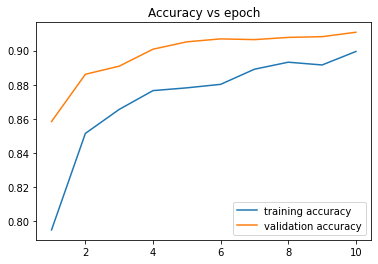

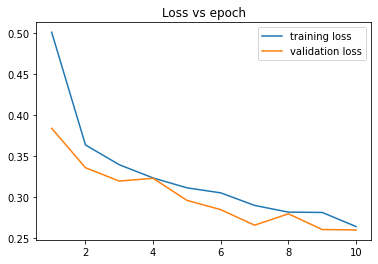

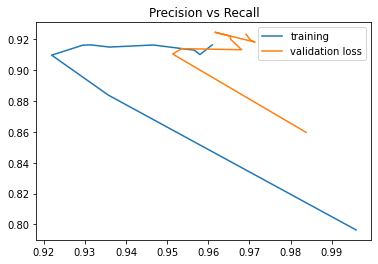

73/73 [==============================] - 2s 29ms/step - loss: 0.2597 - accuracy: 0.9108 - precision: 0.9233 - recall: 0.9692
1
Epoch 1/10
289/289 [==============================] - 6s 15ms/step - loss: 0.3400 - accuracy: 0.8581 - precision: 0.8691 - recall: 0.9668 - val_loss: 0.2675 - val_accuracy: 0.8987 - val_precision: 0.9093 - val_recall: 0.9703
Epoch 2/10
289/289 [==============================] - 3s 12ms/step - loss: 0.2487 - accuracy: 0.9007 - precision: 0.9133 - recall: 0.9666 - val_loss: 0.2559 - val_accuracy: 0.9008 - val_precision: 0.9133 - val_recall: 0.9681
Epoch 3/10
289/289 [==============================] - 3s 12ms/step - loss: 0.2159 - accuracy: 0.9139 - precision: 0.9245 - recall: 0.9708 - val_loss: 0.2482 - val_accuracy: 0.9065 - val_precision: 0.9185 - val_recall: 0.9692
Epoch 4/10
289/289 [==============================] - 3s 12ms/step - loss: 0.1898 - accuracy: 0.9278 - precision: 0.9367 - recall: 0.9749 - val_loss: 0.2453 - val_accuracy: 0.9034 - val_precision: 0

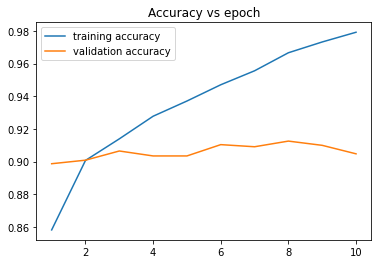

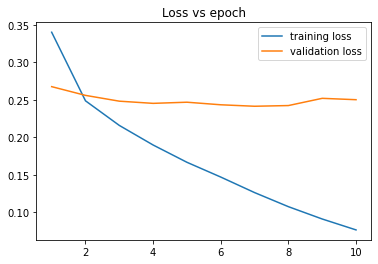

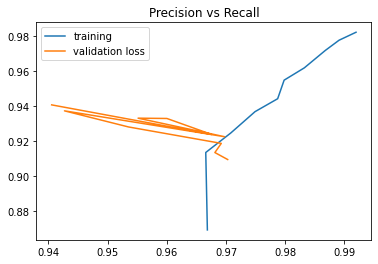

73/73 [==============================] - 0s 5ms/step - loss: 0.2501 - accuracy: 0.9047 - precision: 0.9405 - recall: 0.9405
2
Epoch 1/10
289/289 [==============================] - 6s 15ms/step - loss: 0.3532 - accuracy: 0.8492 - precision: 0.8570 - recall: 0.9723 - val_loss: 0.2792 - val_accuracy: 0.8922 - val_precision: 0.9137 - val_recall: 0.9557
Epoch 2/10
289/289 [==============================] - 4s 14ms/step - loss: 0.2601 - accuracy: 0.8951 - precision: 0.9094 - recall: 0.9640 - val_loss: 0.2431 - val_accuracy: 0.9065 - val_precision: 0.9181 - val_recall: 0.9697
Epoch 3/10
289/289 [==============================] - 4s 14ms/step - loss: 0.2252 - accuracy: 0.9155 - precision: 0.9275 - recall: 0.9693 - val_loss: 0.2283 - val_accuracy: 0.9151 - val_precision: 0.9276 - val_recall: 0.9697
Epoch 4/10
289/289 [==============================] - 4s 14ms/step - loss: 0.2028 - accuracy: 0.9249 - precision: 0.9342 - recall: 0.9741 - val_loss: 0.2192 - val_accuracy: 0.9190 - val_precision: 0.

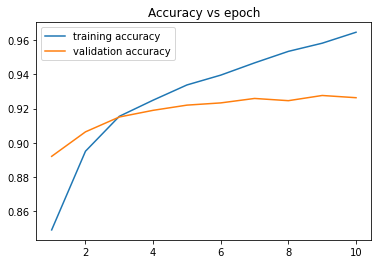

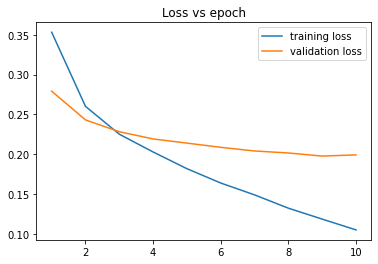

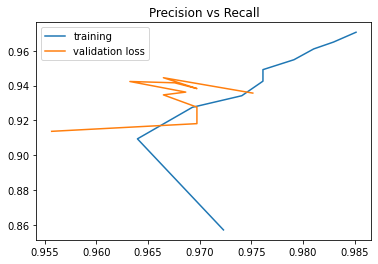

73/73 [==============================] - 0s 6ms/step - loss: 0.1992 - accuracy: 0.9264 - precision: 0.9357 - recall: 0.9751
3
Epoch 1/10
289/289 [==============================] - 31s 80ms/step - loss: 0.2917 - accuracy: 0.8810 - precision: 0.8996 - recall: 0.9569 - val_loss: 0.2349 - val_accuracy: 0.9056 - val_precision: 0.9322 - val_recall: 0.9514
Epoch 2/10
289/289 [==============================] - 20s 71ms/step - loss: 0.2302 - accuracy: 0.9104 - precision: 0.9253 - recall: 0.9651 - val_loss: 0.2239 - val_accuracy: 0.9134 - val_precision: 0.9379 - val_recall: 0.9551
Epoch 3/10
289/289 [==============================] - 21s 71ms/step - loss: 0.2005 - accuracy: 0.9240 - precision: 0.9381 - recall: 0.9681 - val_loss: 0.2163 - val_accuracy: 0.9207 - val_precision: 0.9285 - val_recall: 0.9762
Epoch 4/10
289/289 [==============================] - 20s 70ms/step - loss: 0.1709 - accuracy: 0.9348 - precision: 0.9482 - recall: 0.9709 - val_loss: 0.2033 - val_accuracy: 0.9268 - val_precision

ValueError: ignored

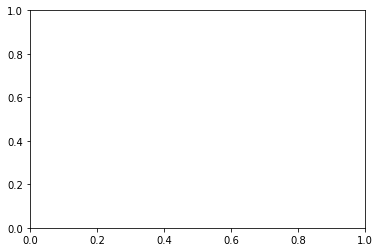

In [ ]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits = 3, shuffle = True)

# Separate the sentences and the labels
sentences, labels = list(pad_rev), list(sentiment_label[0])

# kfold.split() will return set indices for each split
models = [lstm, cnn_1d, dnn, bilstm, cnn_lstm, gru]
precision = [ [] for _ in range(len(models))]
acc = [ [] for _ in range(len(models))]
recall = [ [] for _ in range(len(models))]

callbacks = tf.keras.callbacks.EarlyStopping(
            monitor='val_accuracy',
            min_delta=0,
            patience=5, verbose=2,
            mode='auto',
            restore_best_weights=True)

for train, test in kfold.split(sentences):

    x_train, x_test = [], []
    y_train, y_test = [], []

    for i in train:
        x_train.append(sentences[i])
        y_train.append(labels[i])

    for i in test:
        x_test.append(sentences[i])
        y_test.append(labels[i])

    # Turn the labels into a numpy array
    y_train = np.array(y_train)
    y_test = np.array(y_test)
    x_train = np.reshape(x_train, (len(y_train), 50))
    x_test = np.reshape(x_test, (len(y_test), 50))


    '''lstm = lstm()
    cnn = cnn_1d()
    dnn = dnn()
    bilstm = bilstm()
    cnn_lstm = cnn_lstm()
    gru = gru()
    cnn_gru = cnn_gru()
    cnn_bilstm = cnn_bilstm()
    bigru = bigru()
    cnn_bigru = cnn_bigru()
    tcn = tcn_model()
    tcn_bigru = tcn_bigru()
    tcn_bilstm = tcn_bilstm()
    tcn_lstm = tcn_lstm()
    tcn_gru = tcn_gru()'''

    for i in range(len(models)):
      model = models[i]()
      print(i)
      hist = model.fit(x_train,y_train,epochs=EPOCHS,batch_size = BATCH_SIZE,callbacks=[callbacks], validation_data=(x_test,y_test))

      plt.figure()
      plt.plot(range(1,11), hist.history['accuracy'], label='training accuracy')
      plt.plot(range(1,11),hist.history['val_accuracy'], label='validation accuracy')
      plt.legend()
      plt.title("Accuracy vs epoch")
      plt.show()

      plt.figure()
      plt.plot(range(1,11), hist.history['loss'], label='training loss')
      plt.plot(range(1,11),hist.history['val_loss'], label='validation loss')
      plt.legend()
      plt.title("Loss vs epoch")
      plt.show()

      plt.figure()
      plt.plot(hist.history['recall'], hist.history['precision'], label='training')
      plt.plot(hist.history['val_recall'], hist.history['val_precision'], label='validation loss')
      plt.title("Precision vs Recall")
      plt.legend()
      plt.show()

      l, a, p, r = model.evaluate(x_test, y_test)
      acc[i].append(a)
      precision[i].append(p)
      recall[i].append(r)

mean_acc_list = []
mean_prec_list = []
mean_rec_list = []

for i in range(len(models)):
  mean_acc_list.append(np.array(acc[i]).mean())
  mean_prec_list.append(np.array(precision[i]).mean())
  mean_rec_list.append(np.array(recall[i]).mean())

print(mean_acc_list)
print(mean_prec_list)
print(mean_rec_list)

In [ ]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits = 5, shuffle = True)

# Separate the sentences and the labels
sentences, labels = list(pad_rev), list(sentiment_label[0])

# kfold.split() will return set indices for each split
# [cnn_1d, dnn, bilstm, cnn_lstm, gru, cnn_gru, cnn_bilstm, bigru, cnn_bigru, tcn_model, tcn_bigru, tcn_bilstm, tcn_lstm, tcn_gru, tcn_cnn]
models = [cnn_lstm, gru, tcn_bilstm, tcn_lstm, tcn_gru, tcn_cnn]
precision = [ [] for _ in range(len(models))]
acc = [ [] for _ in range(len(models))]
recall = [ [] for _ in range(len(models))]

callbacks = tf.keras.callbacks.EarlyStopping(
            monitor='val_accuracy',
            min_delta=0,
            patience=5, verbose=2,
            mode='auto',
            restore_best_weights=True)

for train, test in kfold.split(sentences):

    x_train, x_test = [], []
    y_train, y_test = [], []

    for i in train:
        x_train.append(sentences[i])
        y_train.append(labels[i])

    for i in test:
        x_test.append(sentences[i])
        y_test.append(labels[i])

    # Turn the labels into a numpy array
    y_train = np.array(y_train)
    y_test = np.array(y_test)
    x_train = np.reshape(x_train, (len(y_train), 50))
    x_test = np.reshape(x_test, (len(y_test), 50))


    '''lstm = lstm()
    cnn = cnn_1d()
    dnn = dnn()
    bilstm = bilstm()
    cnn_lstm = cnn_lstm()
    gru = gru()
    cnn_gru = cnn_gru()
    cnn_bilstm = cnn_bilstm()
    bigru = bigru()
    cnn_bigru = cnn_bigru()
    tcn = tcn_model()
    tcn_bigru = tcn_bigru()
    tcn_bilstm = tcn_bilstm()
    tcn_lstm = tcn_lstm()
    tcn_gru = tcn_gru()'''

    for i in range(len(models)):
      model = models[i]()
      print(i)
      hist = model.fit(x_train,y_train,epochs=EPOCHS,batch_size = BATCH_SIZE,callbacks=[callbacks], validation_data=(x_test,y_test))
      n = len(hist.history['accuracy'])

      plt.figure()
      plt.plot(range(1,n+1), hist.history['accuracy'], label='training accuracy')
      plt.plot(range(1,n+1),hist.history['val_accuracy'], label='validation accuracy')
      plt.legend()
      plt.title("Accuracy vs epoch")
      plt.show()

      plt.figure()
      plt.plot(range(1,n+1), hist.history['loss'], label='training loss')
      plt.plot(range(1,n+1),hist.history['val_loss'], label='validation loss')
      plt.legend()
      plt.title("Loss vs epoch")
      plt.show()

      plt.figure()
      plt.plot(hist.history['recall'], hist.history['precision'], label='training')
      plt.plot(hist.history['val_recall'], hist.history['val_precision'], label='validation loss')
      plt.title("Precision vs Recall")
      plt.legend()
      plt.show()

      l, a, p, r = model.evaluate(x_test, y_test)
      acc[i].append(a)
      precision[i].append(p)
      recall[i].append(r)

mean_acc_list = []
mean_prec_list = []
mean_rec_list = []

for i in range(len(models)):
  mean_acc_list.append(np.array(acc[i]).mean())
  mean_prec_list.append(np.array(precision[i]).mean())
  mean_rec_list.append(np.array(recall[i]).mean())

print(mean_acc_list)
print(mean_prec_list)
print(mean_rec_list)

289/289 [==============================] - 7s 25ms/step - loss: 0.2794 - accuracy: 0.8890 - precision: 0.9269 - recall: 0.9341 - val_loss: 0.2554 - val_accuracy: 0.9025 - val_precision: 0.9300 - val_recall: 0.9488
Epoch 6/10
178/289 [=================>............] - ETA: 3s - loss: 0.2465 - accuracy: 0.9062 - precision: 0.9306 - recall: 0.9532

KeyboardInterrupt: ignored

In [ ]:
run_models(x_train, y_train, x_test, y_test)

LSTM:
Model: "sequential_11"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_11 (Embedding)    (None, 50, 300)           9720600   
                                                                 
 spatial_dropout1d_6 (Spatia  (None, 50, 300)          0         
 lDropout1D)                                                     
                                                                 
 lstm_8 (LSTM)               (None, 50)                70200     
                                                                 
 dropout_6 (Dropout)         (None, 50)                0         
                                                                 
 dense_17 (Dense)            (None, 1)                 51        
                                                                 
Total params: 9,790,851
Trainable params: 9,790,851
Non-trainable params: 0
_____________________________________

In [ ]:
run_models(x_train, y_train, x_test, y_test)

LSTM:
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_24 (Embedding)    (None, 50, 300)           3624300   
                                                                 
 spatial_dropout1d (SpatialD  (None, 50, 300)          0         
 ropout1D)                                                       
                                                                 
 lstm (LSTM)                 (None, 50)                70200     
                                                                 
 dropout_29 (Dropout)        (None, 50)                0         
                                                                 
 dense_36 (Dense)            (None, 1)                 51        
                                                                 
Total params: 3,694,551
Trainable params: 3,694,551
Non-trainable params: 0
________________________________________

/usr/local/lib/python3.7/dist-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.7/dist-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.7/dist-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


Model: "model_7"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_24 (InputLayer)          [(None, 50)]         0           []                               
                                                                                                  
 embedding_34 (Embedding)       (None, 50, 300)      3624300     ['input_24[0][0]']               
                                                                                                  
 conv1d_15 (Conv1D)             (None, 43, 32)       76832       ['embedding_34[0][0]']           
                                                                                                  
 max_pooling1d_13 (MaxPooling1D  (None, 21, 32)      0           ['conv1d_15[0][0]']              
 )                                                                                          

In [ ]:
BATCH_SIZE = 64
OPT = tf.keras.optimizers.Adam(learning_rate=1e-3)
EPOCHS = 5

0
Epoch 1/5
121/121 [==============================] - 55s 402ms/step - loss: 0.4422 - accuracy: 0.8114 - precision: 0.8287 - recall: 0.9612 - val_loss: 0.3389 - val_accuracy: 0.8640 - val_precision: 0.9174 - val_recall: 0.9117
Epoch 2/5
121/121 [==============================] - 48s 397ms/step - loss: 0.3157 - accuracy: 0.8791 - precision: 0.9064 - recall: 0.9453 - val_loss: 0.2706 - val_accuracy: 0.9020 - val_precision: 0.9167 - val_recall: 0.9648
Epoch 3/5
121/121 [==============================] - 48s 399ms/step - loss: 0.2556 - accuracy: 0.9024 - precision: 0.9225 - recall: 0.9574 - val_loss: 0.2412 - val_accuracy: 0.9015 - val_precision: 0.9034 - val_recall: 0.9814
Epoch 4/5
121/121 [==============================] - 47s 391ms/step - loss: 0.2188 - accuracy: 0.9223 - precision: 0.9391 - recall: 0.9646 - val_loss: 0.2331 - val_accuracy: 0.9093 - val_precision: 0.9149 - val_recall: 0.9772
Epoch 5/5
121/121 [==============================] - 49s 406ms/step - loss: 0.1777 - accuracy:

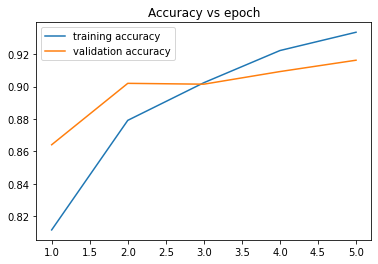

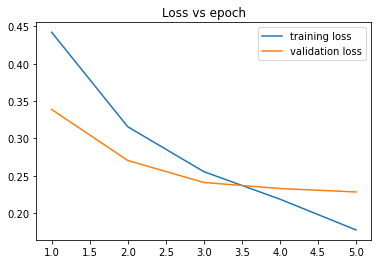

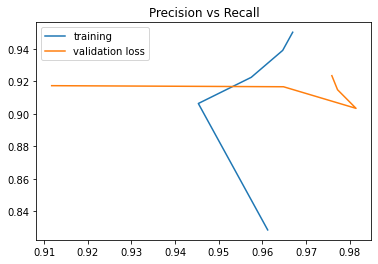

121/121 [==============================] - 3s 27ms/step - loss: 0.2285 - accuracy: 0.9163 - precision: 0.9236 - recall: 0.9759
1
Epoch 1/5
121/121 [==============================] - 3s 18ms/step - loss: 0.3230 - accuracy: 0.8682 - precision: 0.8858 - recall: 0.9574 - val_loss: 0.2464 - val_accuracy: 0.9020 - val_precision: 0.9222 - val_recall: 0.9580
Epoch 2/5
121/121 [==============================] - 2s 14ms/step - loss: 0.1840 - accuracy: 0.9275 - precision: 0.9444 - recall: 0.9655 - val_loss: 0.2386 - val_accuracy: 0.9108 - val_precision: 0.9215 - val_recall: 0.9710
Epoch 3/5
121/121 [==============================] - 2s 15ms/step - loss: 0.1060 - accuracy: 0.9627 - precision: 0.9716 - recall: 0.9817 - val_loss: 0.2602 - val_accuracy: 0.9108 - val_precision: 0.9297 - val_recall: 0.9609
Epoch 4/5
121/121 [==============================] - 2s 15ms/step - loss: 0.0575 - accuracy: 0.9797 - precision: 0.9860 - recall: 0.9885 - val_loss: 0.2877 - val_accuracy: 0.9064 - val_precision: 0.9

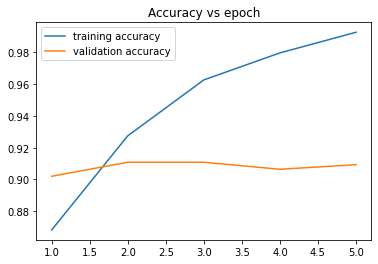

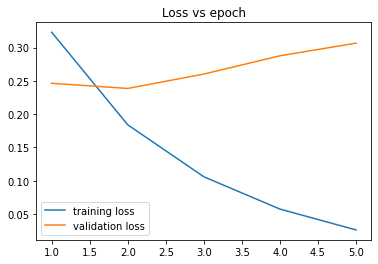

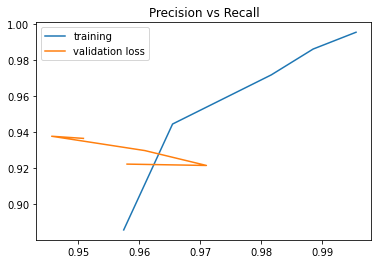

121/121 [==============================] - 1s 6ms/step - loss: 0.3066 - accuracy: 0.9093 - precision: 0.9365 - recall: 0.9508
2
Epoch 1/5
121/121 [==============================] - 4s 21ms/step - loss: 0.3112 - accuracy: 0.8746 - precision: 0.8933 - recall: 0.9563 - val_loss: 0.2263 - val_accuracy: 0.9127 - val_precision: 0.9356 - val_recall: 0.9564
Epoch 2/5
121/121 [==============================] - 2s 17ms/step - loss: 0.1574 - accuracy: 0.9411 - precision: 0.9531 - recall: 0.9738 - val_loss: 0.2164 - val_accuracy: 0.9197 - val_precision: 0.9432 - val_recall: 0.9570
Epoch 3/5
121/121 [==============================] - 2s 17ms/step - loss: 0.0782 - accuracy: 0.9718 - precision: 0.9796 - recall: 0.9849 - val_loss: 0.2408 - val_accuracy: 0.9205 - val_precision: 0.9410 - val_recall: 0.9606
Epoch 4/5
121/121 [==============================] - 2s 16ms/step - loss: 0.0394 - accuracy: 0.9871 - precision: 0.9915 - recall: 0.9923 - val_loss: 0.2960 - val_accuracy: 0.9147 - val_precision: 0.94

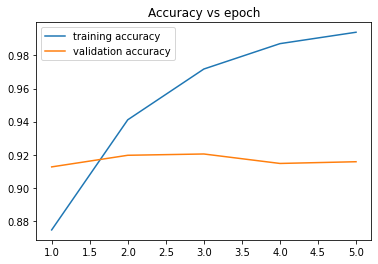

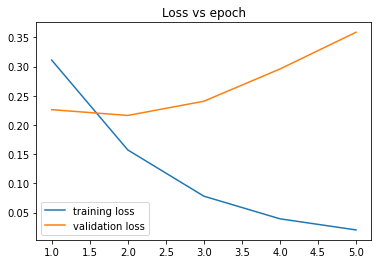

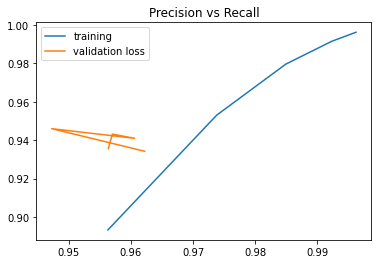

121/121 [==============================] - 1s 6ms/step - loss: 0.3589 - accuracy: 0.9158 - precision: 0.9342 - recall: 0.9622
3
Epoch 1/5
121/121 [==============================] - 20s 101ms/step - loss: 0.2636 - accuracy: 0.8924 - precision: 0.9150 - recall: 0.9530 - val_loss: 0.2112 - val_accuracy: 0.9153 - val_precision: 0.9191 - val_recall: 0.9801
Epoch 2/5
121/121 [==============================] - 10s 79ms/step - loss: 0.1152 - accuracy: 0.9570 - precision: 0.9687 - recall: 0.9774 - val_loss: 0.2197 - val_accuracy: 0.9210 - val_precision: 0.9346 - val_recall: 0.9687
Epoch 3/5
121/121 [==============================] - 9s 79ms/step - loss: 0.0418 - accuracy: 0.9857 - precision: 0.9894 - recall: 0.9926 - val_loss: 0.2787 - val_accuracy: 0.9119 - val_precision: 0.9556 - val_recall: 0.9329
Epoch 4/5
121/121 [==============================] - 9s 78ms/step - loss: 0.0185 - accuracy: 0.9936 - precision: 0.9957 - recall: 0.9962 - val_loss: 0.3270 - val_accuracy: 0.9142 - val_precision: 0

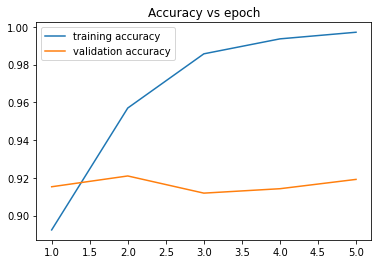

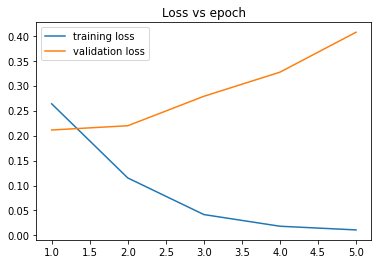

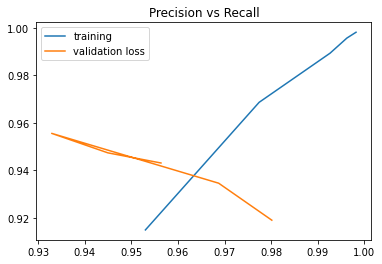

121/121 [==============================] - 3s 24ms/step - loss: 0.4069 - accuracy: 0.9192 - precision: 0.9431 - recall: 0.9564
0
Epoch 1/5
121/121 [==============================] - 54s 417ms/step - loss: 0.3625 - accuracy: 0.8507 - precision: 0.8699 - recall: 0.9540 - val_loss: 0.2881 - val_accuracy: 0.8916 - val_precision: 0.8992 - val_recall: 0.9741
Epoch 2/5
121/121 [==============================] - 48s 398ms/step - loss: 0.2305 - accuracy: 0.9136 - precision: 0.9309 - recall: 0.9623 - val_loss: 0.2450 - val_accuracy: 0.9067 - val_precision: 0.9275 - val_recall: 0.9585
Epoch 3/5
121/121 [==============================] - 49s 404ms/step - loss: 0.1588 - accuracy: 0.9448 - precision: 0.9550 - recall: 0.9762 - val_loss: 0.2314 - val_accuracy: 0.9158 - val_precision: 0.9332 - val_recall: 0.9640
Epoch 4/5
121/121 [==============================] - 48s 397ms/step - loss: 0.1173 - accuracy: 0.9584 - precision: 0.9678 - recall: 0.9801 - val_loss: 0.2688 - val_accuracy: 0.9127 - val_precis

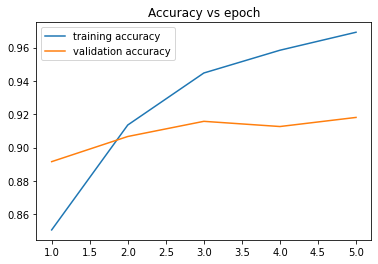

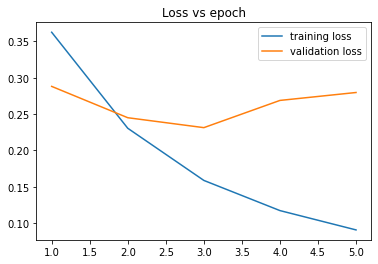

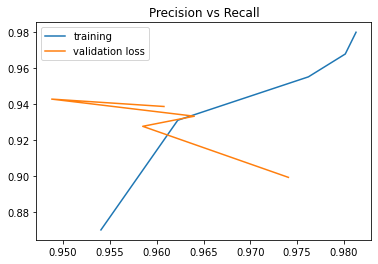

121/121 [==============================] - 4s 30ms/step - loss: 0.2797 - accuracy: 0.9181 - precision: 0.9386 - recall: 0.9608
1
Epoch 1/5
121/121 [==============================] - 3s 19ms/step - loss: 0.3255 - accuracy: 0.8668 - precision: 0.8907 - recall: 0.9481 - val_loss: 0.2736 - val_accuracy: 0.8921 - val_precision: 0.8961 - val_recall: 0.9789
Epoch 2/5
121/121 [==============================] - 2s 14ms/step - loss: 0.1652 - accuracy: 0.9337 - precision: 0.9467 - recall: 0.9710 - val_loss: 0.2474 - val_accuracy: 0.9085 - val_precision: 0.9367 - val_recall: 0.9501
Epoch 3/5
121/121 [==============================] - 2s 14ms/step - loss: 0.0885 - accuracy: 0.9680 - precision: 0.9758 - recall: 0.9841 - val_loss: 0.2569 - val_accuracy: 0.9088 - val_precision: 0.9331 - val_recall: 0.9546
Epoch 4/5
121/121 [==============================] - 2s 14ms/step - loss: 0.0437 - accuracy: 0.9856 - precision: 0.9886 - recall: 0.9933 - val_loss: 0.3216 - val_accuracy: 0.9108 - val_precision: 0.9

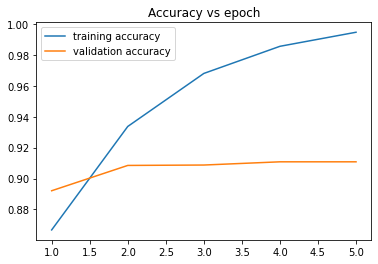

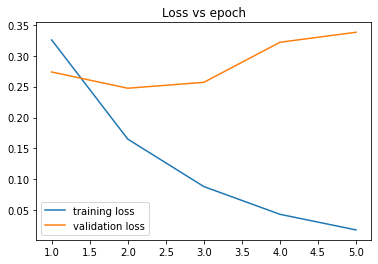

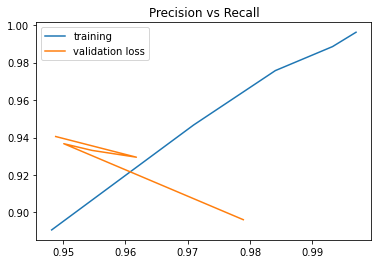

121/121 [==============================] - 1s 5ms/step - loss: 0.3378 - accuracy: 0.9108 - precision: 0.9406 - recall: 0.9488
2
Epoch 1/5
121/121 [==============================] - 4s 20ms/step - loss: 0.3004 - accuracy: 0.8772 - precision: 0.8938 - recall: 0.9588 - val_loss: 0.2452 - val_accuracy: 0.9043 - val_precision: 0.9350 - val_recall: 0.9465
Epoch 2/5
121/121 [==============================] - 2s 15ms/step - loss: 0.1521 - accuracy: 0.9439 - precision: 0.9550 - recall: 0.9751 - val_loss: 0.2276 - val_accuracy: 0.9119 - val_precision: 0.9455 - val_recall: 0.9446
Epoch 3/5
121/121 [==============================] - 2s 15ms/step - loss: 0.0753 - accuracy: 0.9744 - precision: 0.9817 - recall: 0.9860 - val_loss: 0.2558 - val_accuracy: 0.9166 - val_precision: 0.9357 - val_recall: 0.9621
Epoch 4/5
121/121 [==============================] - 2s 16ms/step - loss: 0.0339 - accuracy: 0.9888 - precision: 0.9915 - recall: 0.9944 - val_loss: 0.3053 - val_accuracy: 0.9075 - val_precision: 0.94

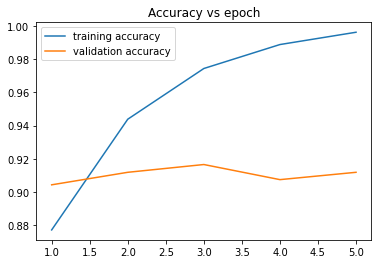

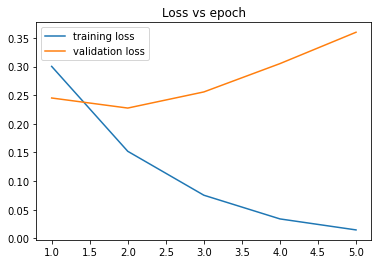

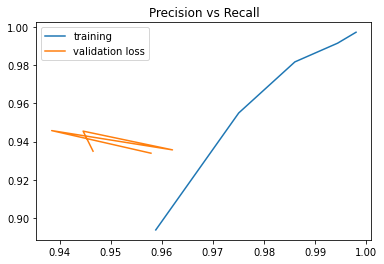

121/121 [==============================] - 1s 7ms/step - loss: 0.3601 - accuracy: 0.9119 - precision: 0.9339 - recall: 0.9579
3
Epoch 1/5
121/121 [==============================] - 20s 102ms/step - loss: 0.2648 - accuracy: 0.8971 - precision: 0.9145 - recall: 0.9598 - val_loss: 0.2325 - val_accuracy: 0.9111 - val_precision: 0.9190 - val_recall: 0.9750
Epoch 2/5
121/121 [==============================] - 10s 81ms/step - loss: 0.1093 - accuracy: 0.9614 - precision: 0.9695 - recall: 0.9821 - val_loss: 0.2240 - val_accuracy: 0.9194 - val_precision: 0.9362 - val_recall: 0.9653
Epoch 3/5
121/121 [==============================] - 10s 79ms/step - loss: 0.0413 - accuracy: 0.9879 - precision: 0.9908 - recall: 0.9939 - val_loss: 0.2885 - val_accuracy: 0.9186 - val_precision: 0.9375 - val_recall: 0.9627
Epoch 4/5
121/121 [==============================] - 9s 76ms/step - loss: 0.0164 - accuracy: 0.9951 - precision: 0.9964 - recall: 0.9974 - val_loss: 0.3211 - val_accuracy: 0.9153 - val_precision: 

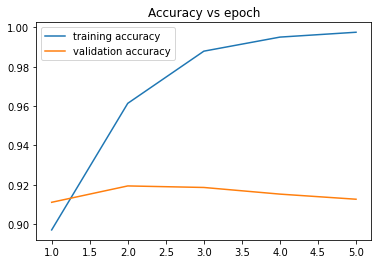

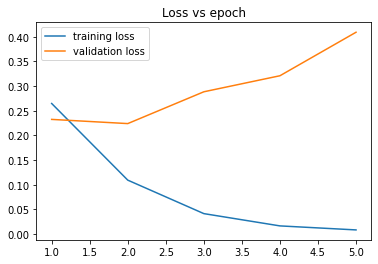

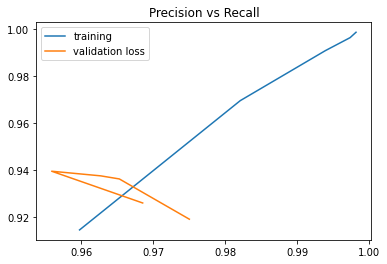

121/121 [==============================] - 3s 26ms/step - loss: 0.4093 - accuracy: 0.9127 - precision: 0.9259 - recall: 0.9686
0
Epoch 1/5
121/121 [==============================] - 54s 419ms/step - loss: 0.3755 - accuracy: 0.8358 - precision: 0.8613 - recall: 0.9474 - val_loss: 0.2628 - val_accuracy: 0.9004 - val_precision: 0.9069 - val_recall: 0.9732
Epoch 2/5
121/121 [==============================] - 49s 403ms/step - loss: 0.2371 - accuracy: 0.9108 - precision: 0.9293 - recall: 0.9617 - val_loss: 0.2339 - val_accuracy: 0.9056 - val_precision: 0.9033 - val_recall: 0.9854
Epoch 3/5
121/121 [==============================] - 49s 403ms/step - loss: 0.1618 - accuracy: 0.9449 - precision: 0.9553 - recall: 0.9768 - val_loss: 0.2390 - val_accuracy: 0.9194 - val_precision: 0.9267 - val_recall: 0.9745
Epoch 4/5
121/121 [==============================] - 48s 397ms/step - loss: 0.1108 - accuracy: 0.9649 - precision: 0.9750 - recall: 0.9813 - val_loss: 0.2617 - val_accuracy: 0.9075 - val_precis

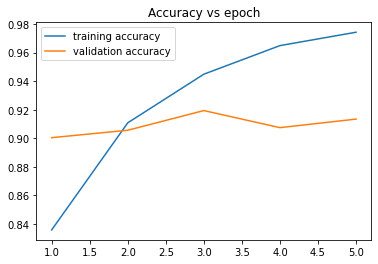

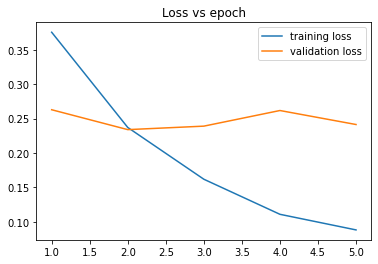

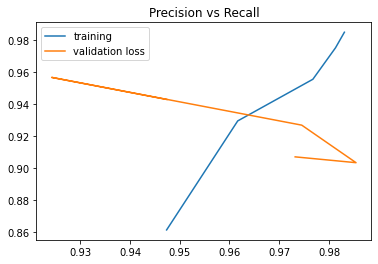

121/121 [==============================] - 4s 32ms/step - loss: 0.2414 - accuracy: 0.9134 - precision: 0.9427 - recall: 0.9474
1
Epoch 1/5
121/121 [==============================] - 3s 18ms/step - loss: 0.3183 - accuracy: 0.8605 - precision: 0.8703 - recall: 0.9703 - val_loss: 0.2290 - val_accuracy: 0.9116 - val_precision: 0.9204 - val_recall: 0.9716
Epoch 2/5
121/121 [==============================] - 2s 15ms/step - loss: 0.1729 - accuracy: 0.9305 - precision: 0.9406 - recall: 0.9747 - val_loss: 0.2072 - val_accuracy: 0.9238 - val_precision: 0.9435 - val_recall: 0.9606
Epoch 3/5
121/121 [==============================] - 2s 16ms/step - loss: 0.0929 - accuracy: 0.9654 - precision: 0.9750 - recall: 0.9820 - val_loss: 0.2261 - val_accuracy: 0.9218 - val_precision: 0.9351 - val_recall: 0.9676
Epoch 4/5
121/121 [==============================] - 2s 15ms/step - loss: 0.0498 - accuracy: 0.9814 - precision: 0.9877 - recall: 0.9891 - val_loss: 0.2634 - val_accuracy: 0.9194 - val_precision: 0.9

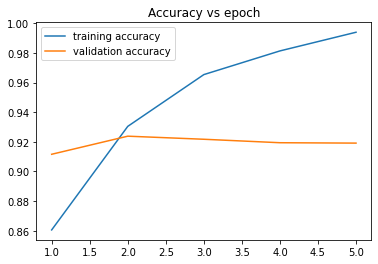

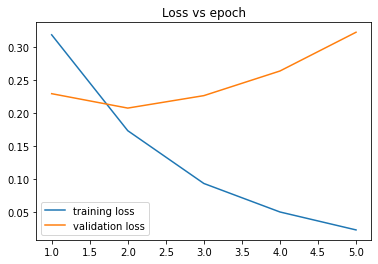

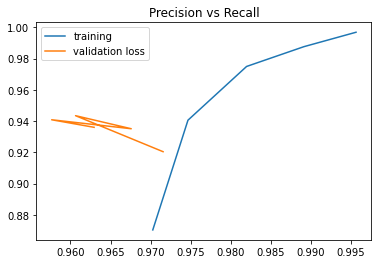

121/121 [==============================] - 1s 6ms/step - loss: 0.3221 - accuracy: 0.9192 - precision: 0.9360 - recall: 0.9630
2
Epoch 1/5
121/121 [==============================] - 4s 19ms/step - loss: 0.3095 - accuracy: 0.8731 - precision: 0.8888 - recall: 0.9618 - val_loss: 0.2308 - val_accuracy: 0.9108 - val_precision: 0.9365 - val_recall: 0.9510
Epoch 2/5
121/121 [==============================] - 2s 16ms/step - loss: 0.1582 - accuracy: 0.9426 - precision: 0.9557 - recall: 0.9734 - val_loss: 0.2106 - val_accuracy: 0.9225 - val_precision: 0.9313 - val_recall: 0.9732
Epoch 3/5
121/121 [==============================] - 2s 17ms/step - loss: 0.0738 - accuracy: 0.9754 - precision: 0.9813 - recall: 0.9881 - val_loss: 0.2606 - val_accuracy: 0.9160 - val_precision: 0.9243 - val_recall: 0.9729
Epoch 4/5
121/121 [==============================] - 2s 16ms/step - loss: 0.0353 - accuracy: 0.9892 - precision: 0.9919 - recall: 0.9946 - val_loss: 0.2843 - val_accuracy: 0.9153 - val_precision: 0.93

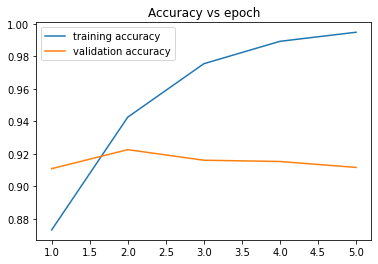

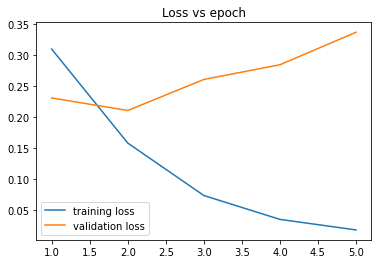

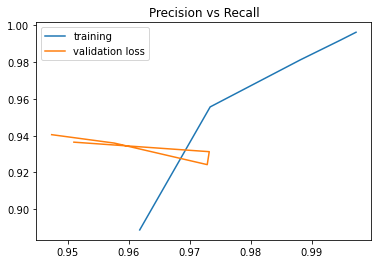

121/121 [==============================] - 1s 7ms/step - loss: 0.3366 - accuracy: 0.9116 - precision: 0.9406 - recall: 0.9474
3
Epoch 1/5
121/121 [==============================] - 21s 99ms/step - loss: 0.2762 - accuracy: 0.8910 - precision: 0.9082 - recall: 0.9608 - val_loss: 0.2063 - val_accuracy: 0.9181 - val_precision: 0.9419 - val_recall: 0.9547
Epoch 2/5
121/121 [==============================] - 10s 81ms/step - loss: 0.1127 - accuracy: 0.9587 - precision: 0.9716 - recall: 0.9769 - val_loss: 0.2526 - val_accuracy: 0.9062 - val_precision: 0.9024 - val_recall: 0.9874
Epoch 3/5
121/121 [==============================] - 10s 80ms/step - loss: 0.0487 - accuracy: 0.9844 - precision: 0.9877 - recall: 0.9929 - val_loss: 0.2552 - val_accuracy: 0.9132 - val_precision: 0.9325 - val_recall: 0.9590
Epoch 4/5
121/121 [==============================] - 9s 77ms/step - loss: 0.0234 - accuracy: 0.9942 - precision: 0.9966 - recall: 0.9961 - val_loss: 0.3063 - val_accuracy: 0.9163 - val_precision: 0

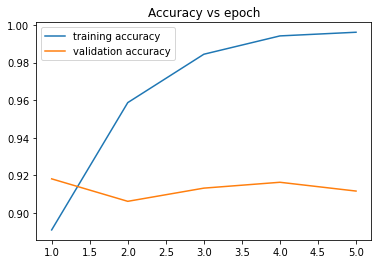

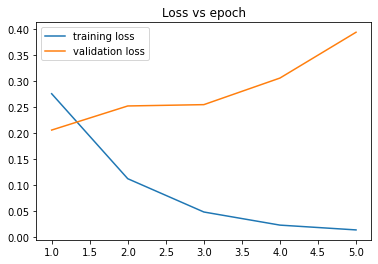

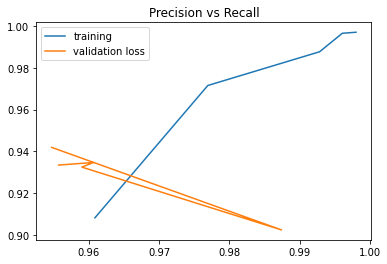

121/121 [==============================] - 3s 26ms/step - loss: 0.3945 - accuracy: 0.9116 - precision: 0.9334 - recall: 0.9557
[0.9159518082936605, 0.9130924542744955, 0.9130924344062805, 0.9144788185755411]
[0.9349484443664551, 0.937680979569753, 0.9362404942512512, 0.9341733654340109]
[0.9613589843114217, 0.9541831612586975, 0.9558262825012207, 0.9601941704750061]


In [ ]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits = 3, shuffle = True)

# Separate the sentences and the labels
sentences, labels = list(pad_rev), list(sentiment_label[0])

# kfold.split() will return set indices for each split
models = [lstm, cnn_1d, dnn, bilstm]
precision = [ [] for _ in range(len(models))]
acc = [ [] for _ in range(len(models))]
recall = [ [] for _ in range(len(models))]

callbacks = tf.keras.callbacks.EarlyStopping(
            monitor='val_accuracy',
            min_delta=0,
            patience=5, verbose=2,
            mode='auto',
            restore_best_weights=True)

for train, test in kfold.split(sentences):

    x_train, x_test = [], []
    y_train, y_test = [], []

    for i in train:
        x_train.append(sentences[i])
        y_train.append(labels[i])

    for i in test:
        x_test.append(sentences[i])
        y_test.append(labels[i])

    # Turn the labels into a numpy array
    y_train = np.array(y_train)
    y_test = np.array(y_test)
    x_train = np.reshape(x_train, (len(y_train), 50))
    x_test = np.reshape(x_test, (len(y_test), 50))


    '''lstm = lstm()
    cnn = cnn_1d()
    dnn = dnn()
    bilstm = bilstm()
    cnn_lstm = cnn_lstm()
    gru = gru()
    cnn_gru = cnn_gru()
    cnn_bilstm = cnn_bilstm()
    bigru = bigru()
    cnn_bigru = cnn_bigru()
    tcn = tcn_model()
    tcn_bigru = tcn_bigru()
    tcn_bilstm = tcn_bilstm()
    tcn_lstm = tcn_lstm()
    tcn_gru = tcn_gru()'''

    for i in range(len(models)):
      model = models[i]()
      print(i)
      hist = model.fit(x_train,y_train,epochs=EPOCHS,batch_size = BATCH_SIZE,callbacks=[callbacks], validation_data=(x_test,y_test))
      n = len(hist.history['accuracy'])

      plt.figure()
      plt.plot(range(1,n+1), hist.history['accuracy'], label='training accuracy')
      plt.plot(range(1,n+1),hist.history['val_accuracy'], label='validation accuracy')
      plt.legend()
      plt.title("Accuracy vs epoch")
      plt.show()

      plt.figure()
      plt.plot(range(1,n+1), hist.history['loss'], label='training loss')
      plt.plot(range(1,n+1),hist.history['val_loss'], label='validation loss')
      plt.legend()
      plt.title("Loss vs epoch")
      plt.show()

      plt.figure()
      plt.plot(hist.history['recall'], hist.history['precision'], label='training')
      plt.plot(hist.history['val_recall'], hist.history['val_precision'], label='validation loss')
      plt.title("Precision vs Recall")
      plt.legend()
      plt.show()

      l, a, p, r = model.evaluate(x_test, y_test)
      acc[i].append(a)
      precision[i].append(p)
      recall[i].append(r)

mean_acc_list = []
mean_prec_list = []
mean_rec_list = []

for i in range(len(models)):
  mean_acc_list.append(np.array(acc[i]).mean())
  mean_prec_list.append(np.array(precision[i]).mean())
  mean_rec_list.append(np.array(recall[i]).mean())

print(mean_acc_list)
print(mean_prec_list)
print(mean_rec_list)

In [ ]:
BATCH_SIZE = 25
OPT = tf.keras.optimizers.Adam(learning_rate=1e-4)
EPOCHS = 10

0
Epoch 1/10
308/308 [==============================] - 23s 31ms/step - loss: 0.4904 - accuracy: 0.7935 - precision: 0.7935 - recall: 1.0000 - val_loss: 0.4653 - val_accuracy: 0.7988 - val_precision: 0.7988 - val_recall: 1.0000
Epoch 2/10
308/308 [==============================] - 8s 25ms/step - loss: 0.4547 - accuracy: 0.7935 - precision: 0.7935 - recall: 1.0000 - val_loss: 0.4411 - val_accuracy: 0.7988 - val_precision: 0.7988 - val_recall: 1.0000
Epoch 3/10
308/308 [==============================] - 7s 24ms/step - loss: 0.4319 - accuracy: 0.7935 - precision: 0.7935 - recall: 1.0000 - val_loss: 0.4247 - val_accuracy: 0.7988 - val_precision: 0.7988 - val_recall: 1.0000
Epoch 4/10
308/308 [==============================] - 8s 25ms/step - loss: 0.4148 - accuracy: 0.7935 - precision: 0.7935 - recall: 1.0000 - val_loss: 0.4142 - val_accuracy: 0.7988 - val_precision: 0.7988 - val_recall: 1.0000
Epoch 5/10
308/308 [==============================] - 7s 24ms/step - loss: 0.4016 - accuracy: 0.7

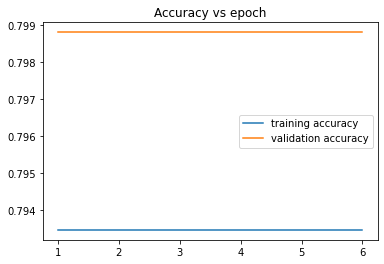

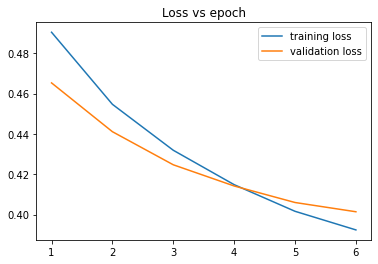

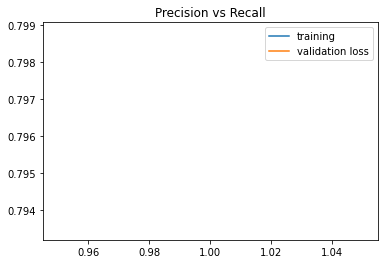

121/121 [==============================] - 1s 9ms/step - loss: 0.4653 - accuracy: 0.7988 - precision: 0.7988 - recall: 1.0000
1
Epoch 1/10
308/308 [==============================] - 19s 45ms/step - loss: 0.6750 - accuracy: 0.7926 - precision: 0.8737 - recall: 0.8634 - val_loss: 0.6605 - val_accuracy: 0.8456 - val_precision: 0.8744 - val_recall: 0.9421
Epoch 2/10
308/308 [==============================] - 12s 40ms/step - loss: 0.6467 - accuracy: 0.8726 - precision: 0.9177 - recall: 0.9222 - val_loss: 0.6412 - val_accuracy: 0.8591 - val_precision: 0.9060 - val_recall: 0.9190
Epoch 3/10
308/308 [==============================] - 13s 41ms/step - loss: 0.6293 - accuracy: 0.8841 - precision: 0.9302 - recall: 0.9232 - val_loss: 0.6263 - val_accuracy: 0.8612 - val_precision: 0.9083 - val_recall: 0.9190
Epoch 4/10
308/308 [==============================] - 12s 40ms/step - loss: 0.6149 - accuracy: 0.8900 - precision: 0.9313 - recall: 0.9301 - val_loss: 0.6130 - val_accuracy: 0.8750 - val_precisi

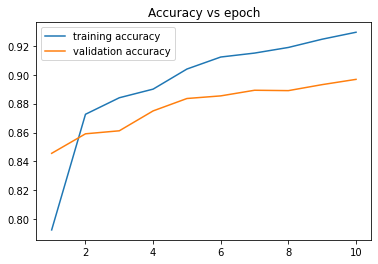

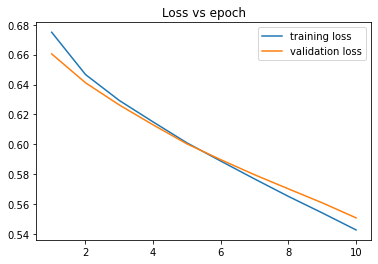

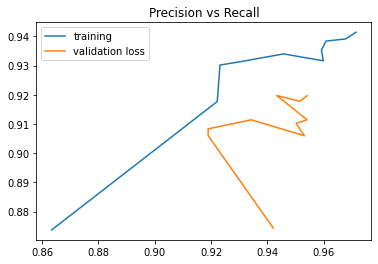

121/121 [==============================] - 2s 13ms/step - loss: 0.5507 - accuracy: 0.8968 - precision: 0.9197 - recall: 0.9541
2
Epoch 1/10
308/308 [==============================] - 31s 77ms/step - loss: 0.2855 - accuracy: 0.8863 - precision: 0.9035 - recall: 0.9590 - val_loss: 0.2731 - val_accuracy: 0.8856 - val_precision: 0.9097 - val_recall: 0.9512
Epoch 2/10
308/308 [==============================] - 22s 71ms/step - loss: 0.2231 - accuracy: 0.9128 - precision: 0.9299 - recall: 0.9627 - val_loss: 0.2541 - val_accuracy: 0.8971 - val_precision: 0.9150 - val_recall: 0.9603
Epoch 3/10
308/308 [==============================] - 22s 71ms/step - loss: 0.1959 - accuracy: 0.9245 - precision: 0.9386 - recall: 0.9682 - val_loss: 0.2417 - val_accuracy: 0.9033 - val_precision: 0.9305 - val_recall: 0.9499
Epoch 4/10
308/308 [==============================] - 22s 71ms/step - loss: 0.1662 - accuracy: 0.9388 - precision: 0.9523 - recall: 0.9715 - val_loss: 0.2367 - val_accuracy: 0.9108 - val_precis

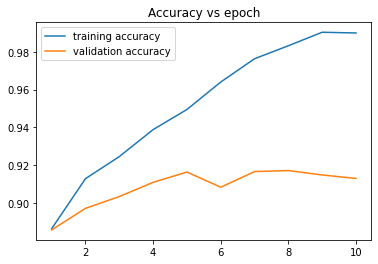

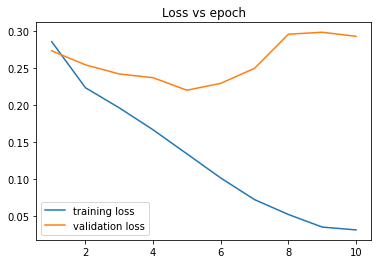

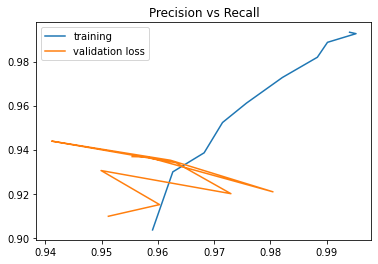

121/121 [==============================] - 3s 25ms/step - loss: 0.2927 - accuracy: 0.9129 - precision: 0.9368 - recall: 0.9554
3
Epoch 1/10
308/308 [==============================] - 19s 46ms/step - loss: 0.6748 - accuracy: 0.7121 - precision: 0.8396 - recall: 0.7877 - val_loss: 0.6002 - val_accuracy: 0.8399 - val_precision: 0.8608 - val_recall: 0.9538
Epoch 2/10
308/308 [==============================] - 13s 42ms/step - loss: 0.5552 - accuracy: 0.8499 - precision: 0.9110 - recall: 0.8986 - val_loss: 0.5097 - val_accuracy: 0.8895 - val_precision: 0.8945 - val_recall: 0.9769
Epoch 3/10
308/308 [==============================] - 13s 41ms/step - loss: 0.4645 - accuracy: 0.9251 - precision: 0.9434 - recall: 0.9635 - val_loss: 0.4395 - val_accuracy: 0.9095 - val_precision: 0.9270 - val_recall: 0.9626
Epoch 4/10
308/308 [==============================] - 12s 41ms/step - loss: 0.3888 - accuracy: 0.9528 - precision: 0.9595 - recall: 0.9820 - val_loss: 0.3924 - val_accuracy: 0.9132 - val_precis

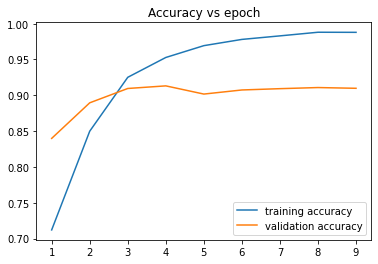

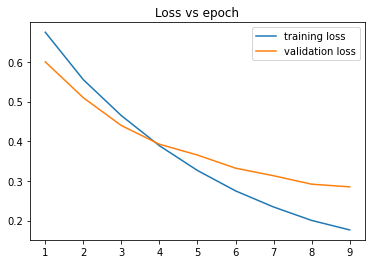

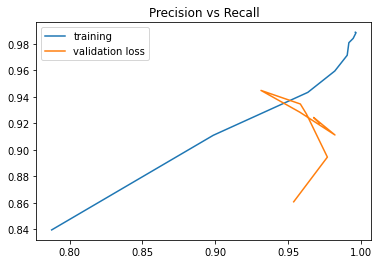

121/121 [==============================] - 2s 13ms/step - loss: 0.3924 - accuracy: 0.9132 - precision: 0.9346 - recall: 0.9583
4
Epoch 1/10
308/308 [==============================] - 14s 31ms/step - loss: 0.3022 - accuracy: 0.8816 - precision: 0.9010 - recall: 0.9558 - val_loss: 0.2867 - val_accuracy: 0.8825 - val_precision: 0.8899 - val_recall: 0.9733
Epoch 2/10
308/308 [==============================] - 8s 26ms/step - loss: 0.2433 - accuracy: 0.9033 - precision: 0.9203 - recall: 0.9613 - val_loss: 0.2665 - val_accuracy: 0.8906 - val_precision: 0.9113 - val_recall: 0.9561
Epoch 3/10
308/308 [==============================] - 8s 26ms/step - loss: 0.2130 - accuracy: 0.9199 - precision: 0.9370 - recall: 0.9640 - val_loss: 0.2577 - val_accuracy: 0.8952 - val_precision: 0.9058 - val_recall: 0.9697
Epoch 4/10
308/308 [==============================] - 8s 26ms/step - loss: 0.1829 - accuracy: 0.9288 - precision: 0.9449 - recall: 0.9666 - val_loss: 0.2458 - val_accuracy: 0.8994 - val_precision

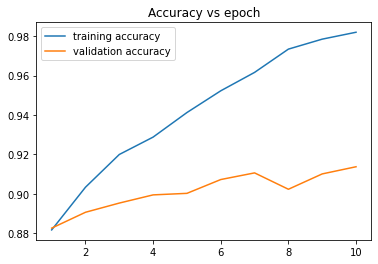

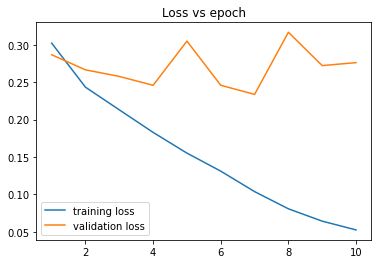

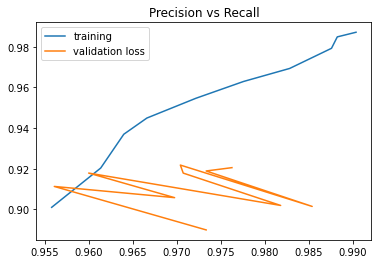

121/121 [==============================] - 2s 12ms/step - loss: 0.2762 - accuracy: 0.9137 - precision: 0.9205 - recall: 0.9762
5
Epoch 1/10
308/308 [==============================] - 23s 54ms/step - loss: 0.6753 - accuracy: 0.8032 - precision: 0.8677 - recall: 0.8873 - val_loss: 0.6576 - val_accuracy: 0.8560 - val_precision: 0.8774 - val_recall: 0.9528
Epoch 2/10
308/308 [==============================] - 15s 47ms/step - loss: 0.6420 - accuracy: 0.8850 - precision: 0.9138 - recall: 0.9441 - val_loss: 0.6378 - val_accuracy: 0.8734 - val_precision: 0.9201 - val_recall: 0.9216
Epoch 3/10
308/308 [==============================] - 15s 47ms/step - loss: 0.6241 - accuracy: 0.9011 - precision: 0.9263 - recall: 0.9510 - val_loss: 0.6234 - val_accuracy: 0.8812 - val_precision: 0.9065 - val_recall: 0.9492
Epoch 4/10
308/308 [==============================] - 16s 53ms/step - loss: 0.6106 - accuracy: 0.9089 - precision: 0.9265 - recall: 0.9615 - val_loss: 0.6112 - val_accuracy: 0.8885 - val_precis

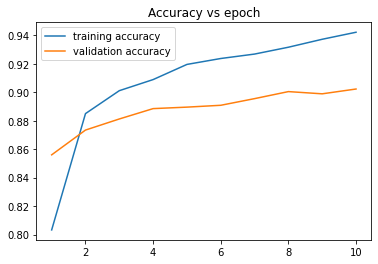

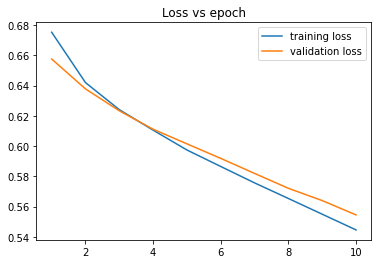

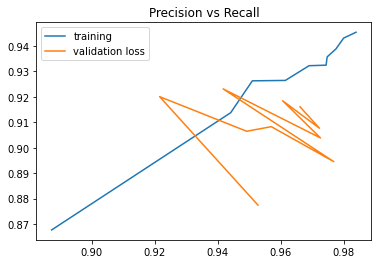

121/121 [==============================] - 2s 20ms/step - loss: 0.5545 - accuracy: 0.9023 - precision: 0.9161 - recall: 0.9662
0
Epoch 1/10
308/308 [==============================] - 13s 31ms/step - loss: 0.6941 - accuracy: 0.7476 - precision: 0.8383 - recall: 0.8451 - val_loss: 0.6601 - val_accuracy: 0.8305 - val_precision: 0.8484 - val_recall: 0.9590
Epoch 2/10
308/308 [==============================] - 8s 27ms/step - loss: 0.6532 - accuracy: 0.8241 - precision: 0.8456 - recall: 0.9524 - val_loss: 0.6396 - val_accuracy: 0.8479 - val_precision: 0.8630 - val_recall: 0.9622
Epoch 3/10
308/308 [==============================] - 8s 27ms/step - loss: 0.6351 - accuracy: 0.8397 - precision: 0.8638 - recall: 0.9476 - val_loss: 0.6224 - val_accuracy: 0.8630 - val_precision: 0.8752 - val_recall: 0.9661
Epoch 4/10
308/308 [==============================] - 8s 26ms/step - loss: 0.6182 - accuracy: 0.8604 - precision: 0.8816 - recall: 0.9520 - val_loss: 0.6075 - val_accuracy: 0.8734 - val_precision

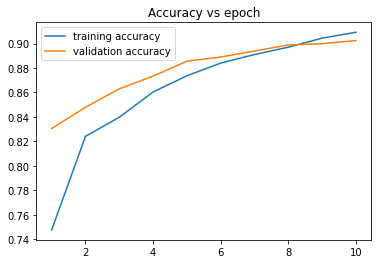

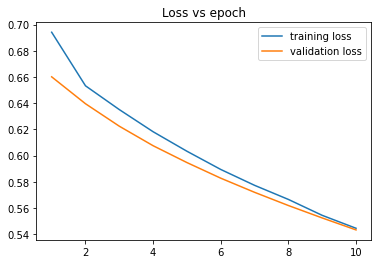

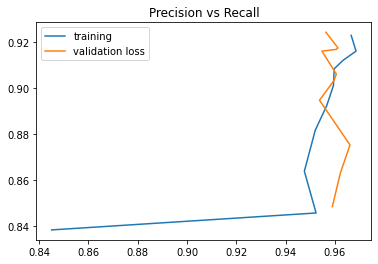

121/121 [==============================] - 1s 9ms/step - loss: 0.5433 - accuracy: 0.9025 - precision: 0.9241 - recall: 0.9564
1
Epoch 1/10
308/308 [==============================] - 19s 46ms/step - loss: 0.6958 - accuracy: 0.7064 - precision: 0.8346 - recall: 0.7859 - val_loss: 0.6622 - val_accuracy: 0.8256 - val_precision: 0.8318 - val_recall: 0.9795
Epoch 2/10
308/308 [==============================] - 13s 43ms/step - loss: 0.6637 - accuracy: 0.7937 - precision: 0.8336 - recall: 0.9249 - val_loss: 0.6457 - val_accuracy: 0.8326 - val_precision: 0.8383 - val_recall: 0.9792
Epoch 3/10
308/308 [==============================] - 13s 43ms/step - loss: 0.6475 - accuracy: 0.8048 - precision: 0.8395 - recall: 0.9324 - val_loss: 0.6281 - val_accuracy: 0.8451 - val_precision: 0.8488 - val_recall: 0.9805
Epoch 4/10
308/308 [==============================] - 13s 43ms/step - loss: 0.6315 - accuracy: 0.8188 - precision: 0.8518 - recall: 0.9343 - val_loss: 0.6095 - val_accuracy: 0.8648 - val_precisi

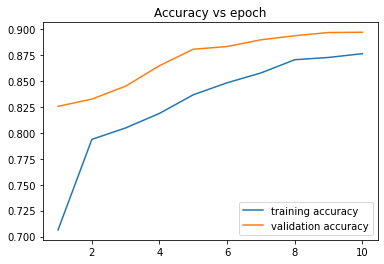

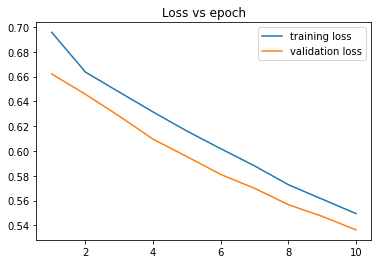

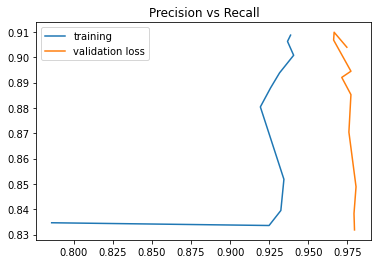

121/121 [==============================] - 2s 13ms/step - loss: 0.5363 - accuracy: 0.8971 - precision: 0.9039 - recall: 0.9746
2
Epoch 1/10
308/308 [==============================] - 32s 78ms/step - loss: 0.3043 - accuracy: 0.8734 - precision: 0.8915 - recall: 0.9569 - val_loss: 0.2422 - val_accuracy: 0.9080 - val_precision: 0.9369 - val_recall: 0.9485
Epoch 2/10
308/308 [==============================] - 22s 72ms/step - loss: 0.2349 - accuracy: 0.9089 - precision: 0.9268 - recall: 0.9612 - val_loss: 0.2350 - val_accuracy: 0.9114 - val_precision: 0.9239 - val_recall: 0.9687
Epoch 3/10
308/308 [==============================] - 22s 72ms/step - loss: 0.2011 - accuracy: 0.9233 - precision: 0.9385 - recall: 0.9668 - val_loss: 0.2120 - val_accuracy: 0.9155 - val_precision: 0.9389 - val_recall: 0.9564
Epoch 4/10
308/308 [==============================] - 22s 72ms/step - loss: 0.1653 - accuracy: 0.9410 - precision: 0.9548 - recall: 0.9717 - val_loss: 0.2208 - val_accuracy: 0.9184 - val_precis

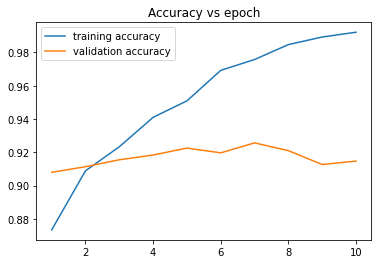

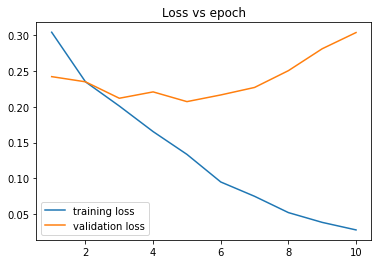

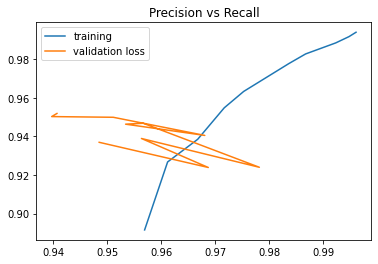

121/121 [==============================] - 3s 25ms/step - loss: 0.3038 - accuracy: 0.9147 - precision: 0.9519 - recall: 0.9407
3
Epoch 1/10
308/308 [==============================] - 19s 46ms/step - loss: 0.3785 - accuracy: 0.8274 - precision: 0.8267 - recall: 0.9902 - val_loss: 0.3100 - val_accuracy: 0.8960 - val_precision: 0.8943 - val_recall: 0.9863
Epoch 2/10
308/308 [==============================] - 13s 43ms/step - loss: 0.3029 - accuracy: 0.8911 - precision: 0.8948 - recall: 0.9777 - val_loss: 0.2876 - val_accuracy: 0.9036 - val_precision: 0.9111 - val_recall: 0.9743
Epoch 3/10
308/308 [==============================] - 13s 42ms/step - loss: 0.2510 - accuracy: 0.9245 - precision: 0.9284 - recall: 0.9805 - val_loss: 0.2617 - val_accuracy: 0.9197 - val_precision: 0.9432 - val_recall: 0.9570
Epoch 4/10
308/308 [==============================] - 13s 42ms/step - loss: 0.2085 - accuracy: 0.9403 - precision: 0.9413 - recall: 0.9864 - val_loss: 0.2572 - val_accuracy: 0.9194 - val_precis

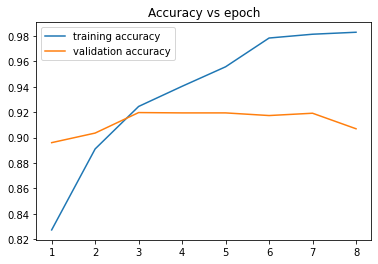

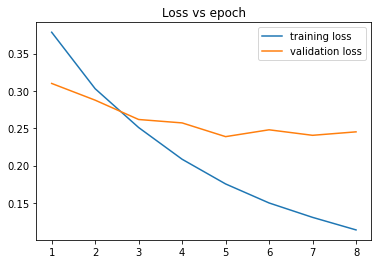

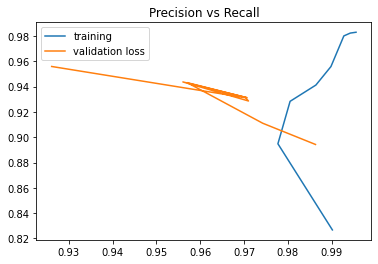

121/121 [==============================] - 2s 14ms/step - loss: 0.2617 - accuracy: 0.9197 - precision: 0.9432 - recall: 0.9570
4
Epoch 1/10
308/308 [==============================] - 12s 30ms/step - loss: 0.3203 - accuracy: 0.8712 - precision: 0.8914 - recall: 0.9540 - val_loss: 0.2618 - val_accuracy: 0.9033 - val_precision: 0.9224 - val_recall: 0.9596
Epoch 2/10
308/308 [==============================] - 8s 26ms/step - loss: 0.2629 - accuracy: 0.8985 - precision: 0.9174 - recall: 0.9584 - val_loss: 0.2487 - val_accuracy: 0.9020 - val_precision: 0.9062 - val_recall: 0.9785
Epoch 3/10
308/308 [==============================] - 8s 26ms/step - loss: 0.2265 - accuracy: 0.9123 - precision: 0.9281 - recall: 0.9641 - val_loss: 0.2326 - val_accuracy: 0.9088 - val_precision: 0.9237 - val_recall: 0.9655
Epoch 4/10
308/308 [==============================] - 8s 26ms/step - loss: 0.2016 - accuracy: 0.9259 - precision: 0.9401 - recall: 0.9684 - val_loss: 0.2429 - val_accuracy: 0.9075 - val_precision

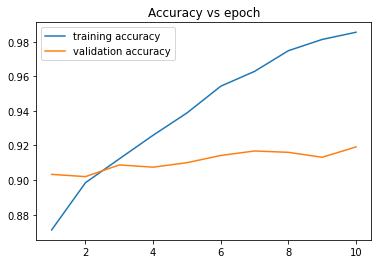

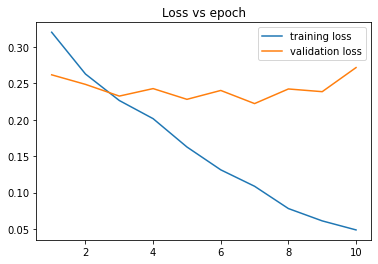

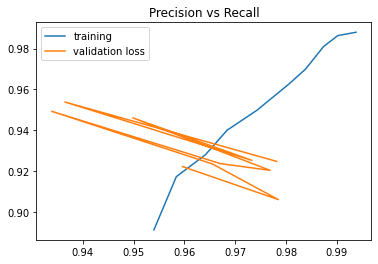

121/121 [==============================] - 1s 10ms/step - loss: 0.2718 - accuracy: 0.9192 - precision: 0.9249 - recall: 0.9782
5
Epoch 1/10
308/308 [==============================] - 25s 57ms/step - loss: 0.6597 - accuracy: 0.7733 - precision: 0.8085 - recall: 0.9363 - val_loss: 0.6231 - val_accuracy: 0.8469 - val_precision: 0.8525 - val_recall: 0.9772
Epoch 2/10
308/308 [==============================] - 15s 50ms/step - loss: 0.6051 - accuracy: 0.8551 - precision: 0.8684 - recall: 0.9635 - val_loss: 0.5784 - val_accuracy: 0.8874 - val_precision: 0.9051 - val_recall: 0.9596
Epoch 3/10
308/308 [==============================] - 15s 48ms/step - loss: 0.5675 - accuracy: 0.8873 - precision: 0.9048 - recall: 0.9589 - val_loss: 0.5525 - val_accuracy: 0.8994 - val_precision: 0.9106 - val_recall: 0.9691
Epoch 4/10
308/308 [==============================] - 15s 48ms/step - loss: 0.5428 - accuracy: 0.9025 - precision: 0.9161 - recall: 0.9656 - val_loss: 0.5337 - val_accuracy: 0.9025 - val_precis

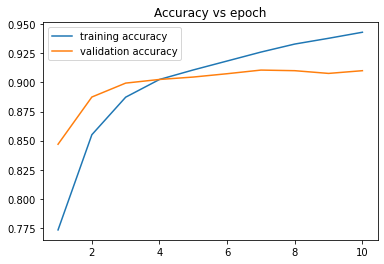

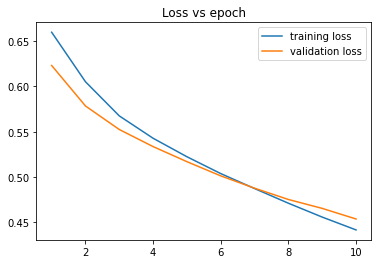

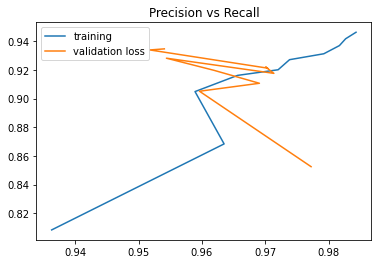

121/121 [==============================] - 3s 21ms/step - loss: 0.4539 - accuracy: 0.9101 - precision: 0.9346 - recall: 0.9541
0
Epoch 1/10
308/308 [==============================] - 13s 34ms/step - loss: 0.6106 - accuracy: 0.8076 - precision: 0.8288 - recall: 0.9567 - val_loss: 0.5888 - val_accuracy: 0.8256 - val_precision: 0.8280 - val_recall: 0.9832
Epoch 2/10
308/308 [==============================] - 9s 30ms/step - loss: 0.5705 - accuracy: 0.8460 - precision: 0.8480 - recall: 0.9834 - val_loss: 0.5602 - val_accuracy: 0.8474 - val_precision: 0.8503 - val_recall: 0.9789
Epoch 3/10
308/308 [==============================] - 9s 30ms/step - loss: 0.5459 - accuracy: 0.8635 - precision: 0.8649 - recall: 0.9826 - val_loss: 0.5384 - val_accuracy: 0.8628 - val_precision: 0.8589 - val_recall: 0.9885
Epoch 4/10
308/308 [==============================] - 9s 31ms/step - loss: 0.5260 - accuracy: 0.8746 - precision: 0.8746 - recall: 0.9840 - val_loss: 0.5207 - val_accuracy: 0.8734 - val_precision

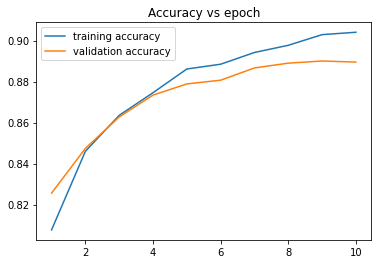

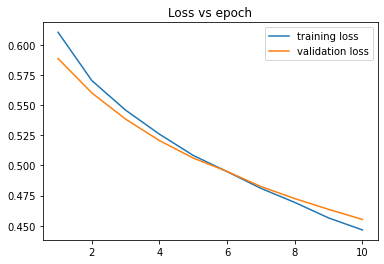

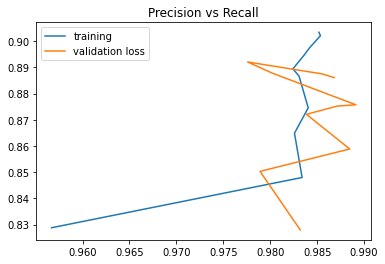

121/121 [==============================] - 1s 10ms/step - loss: 0.4552 - accuracy: 0.8895 - precision: 0.8861 - recall: 0.9868
1
Epoch 1/10
308/308 [==============================] - 19s 48ms/step - loss: 0.4584 - accuracy: 0.7984 - precision: 0.7984 - recall: 1.0000 - val_loss: 0.4363 - val_accuracy: 0.7889 - val_precision: 0.7889 - val_recall: 1.0000
Epoch 2/10
308/308 [==============================] - 14s 44ms/step - loss: 0.4210 - accuracy: 0.7984 - precision: 0.7984 - recall: 1.0000 - val_loss: 0.4123 - val_accuracy: 0.7889 - val_precision: 0.7889 - val_recall: 1.0000
Epoch 3/10
308/308 [==============================] - 14s 44ms/step - loss: 0.4027 - accuracy: 0.7984 - precision: 0.7984 - recall: 1.0000 - val_loss: 0.3994 - val_accuracy: 0.7889 - val_precision: 0.7889 - val_recall: 1.0000
Epoch 4/10
308/308 [==============================] - 13s 44ms/step - loss: 0.3867 - accuracy: 0.7984 - precision: 0.7984 - recall: 1.0000 - val_loss: 0.3861 - val_accuracy: 0.7889 - val_precis

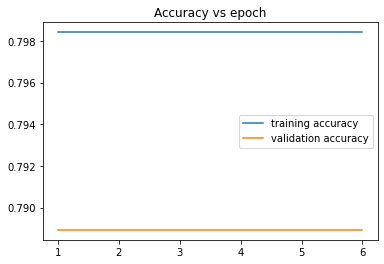

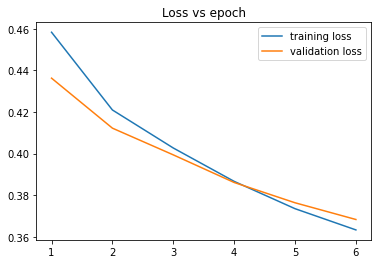

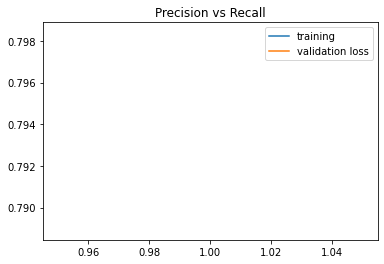

121/121 [==============================] - 2s 14ms/step - loss: 0.4363 - accuracy: 0.7889 - precision: 0.7889 - recall: 1.0000
2
Epoch 1/10
308/308 [==============================] - 32s 79ms/step - loss: 0.3040 - accuracy: 0.8786 - precision: 0.8956 - recall: 0.9598 - val_loss: 0.2533 - val_accuracy: 0.9010 - val_precision: 0.9162 - val_recall: 0.9624
Epoch 2/10
308/308 [==============================] - 22s 73ms/step - loss: 0.2299 - accuracy: 0.9120 - precision: 0.9286 - recall: 0.9639 - val_loss: 0.2356 - val_accuracy: 0.9069 - val_precision: 0.9182 - val_recall: 0.9684
Epoch 3/10
308/308 [==============================] - 22s 72ms/step - loss: 0.1987 - accuracy: 0.9258 - precision: 0.9419 - recall: 0.9666 - val_loss: 0.2219 - val_accuracy: 0.9124 - val_precision: 0.9266 - val_recall: 0.9654
Epoch 4/10
308/308 [==============================] - 22s 72ms/step - loss: 0.1654 - accuracy: 0.9390 - precision: 0.9525 - recall: 0.9722 - val_loss: 0.2137 - val_accuracy: 0.9168 - val_precis

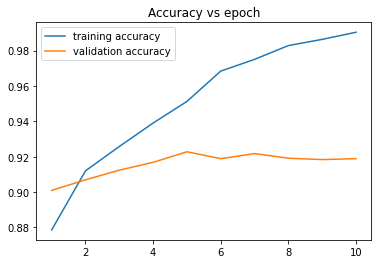

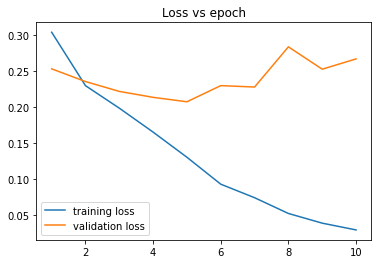

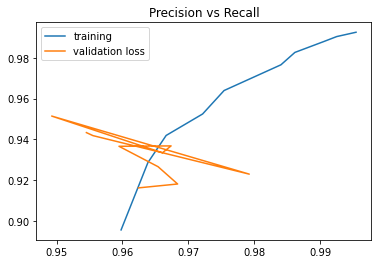

121/121 [==============================] - 3s 26ms/step - loss: 0.2075 - accuracy: 0.9228 - precision: 0.9368 - recall: 0.9674
3
Epoch 1/10
308/308 [==============================] - 20s 48ms/step - loss: 0.6421 - accuracy: 0.8178 - precision: 0.8684 - recall: 0.9097 - val_loss: 0.5842 - val_accuracy: 0.8851 - val_precision: 0.9200 - val_recall: 0.9357
Epoch 2/10
308/308 [==============================] - 14s 44ms/step - loss: 0.5513 - accuracy: 0.8821 - precision: 0.9106 - recall: 0.9451 - val_loss: 0.5090 - val_accuracy: 0.8971 - val_precision: 0.9283 - val_recall: 0.9423
Epoch 3/10
308/308 [==============================] - 14s 44ms/step - loss: 0.4699 - accuracy: 0.9159 - precision: 0.9310 - recall: 0.9663 - val_loss: 0.4426 - val_accuracy: 0.9098 - val_precision: 0.9177 - val_recall: 0.9730
Epoch 4/10
308/308 [==============================] - 13s 44ms/step - loss: 0.3941 - accuracy: 0.9474 - precision: 0.9535 - recall: 0.9819 - val_loss: 0.3923 - val_accuracy: 0.9124 - val_precis

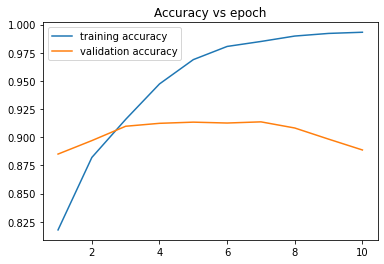

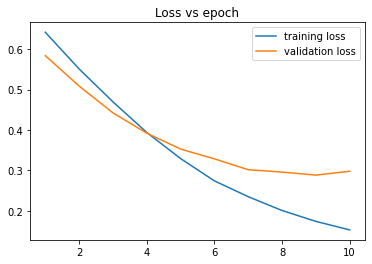

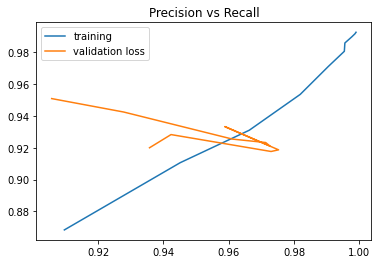

121/121 [==============================] - 2s 14ms/step - loss: 0.2981 - accuracy: 0.8887 - precision: 0.9509 - recall: 0.9058
4
Epoch 1/10
308/308 [==============================] - 14s 34ms/step - loss: 0.3179 - accuracy: 0.8705 - precision: 0.8918 - recall: 0.9536 - val_loss: 0.2713 - val_accuracy: 0.8916 - val_precision: 0.9063 - val_recall: 0.9621
Epoch 2/10
308/308 [==============================] - 9s 30ms/step - loss: 0.2501 - accuracy: 0.9023 - precision: 0.9181 - recall: 0.9635 - val_loss: 0.2672 - val_accuracy: 0.8916 - val_precision: 0.9337 - val_recall: 0.9285
Epoch 3/10
308/308 [==============================] - 9s 31ms/step - loss: 0.2219 - accuracy: 0.9151 - precision: 0.9307 - recall: 0.9657 - val_loss: 0.2458 - val_accuracy: 0.9002 - val_precision: 0.9204 - val_recall: 0.9562
Epoch 4/10
308/308 [==============================] - 9s 29ms/step - loss: 0.1897 - accuracy: 0.9281 - precision: 0.9421 - recall: 0.9696 - val_loss: 0.2415 - val_accuracy: 0.9043 - val_precision

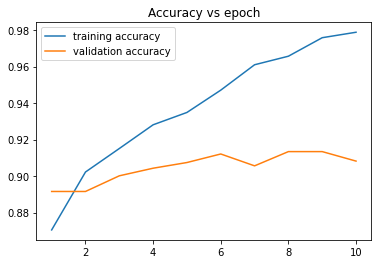

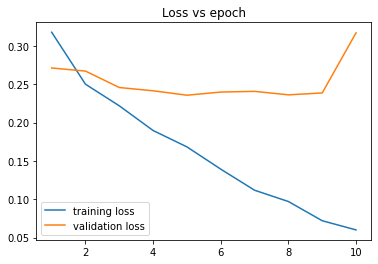

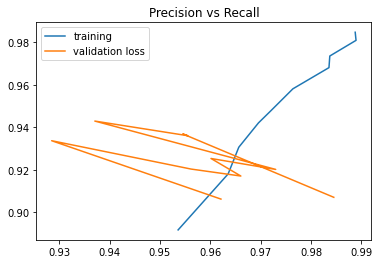

121/121 [==============================] - 1s 12ms/step - loss: 0.3172 - accuracy: 0.9082 - precision: 0.9071 - recall: 0.9845
5
Epoch 1/10
308/308 [==============================] - 27s 64ms/step - loss: 0.4795 - accuracy: 0.8037 - precision: 0.8061 - recall: 0.9930 - val_loss: 0.4471 - val_accuracy: 0.7889 - val_precision: 0.7889 - val_recall: 1.0000
Epoch 2/10
308/308 [==============================] - 18s 58ms/step - loss: 0.4325 - accuracy: 0.8443 - precision: 0.8461 - recall: 0.9839 - val_loss: 0.4117 - val_accuracy: 0.8893 - val_precision: 0.9020 - val_recall: 0.9644
Epoch 3/10
308/308 [==============================] - 17s 54ms/step - loss: 0.4070 - accuracy: 0.8839 - precision: 0.8992 - recall: 0.9626 - val_loss: 0.4095 - val_accuracy: 0.8958 - val_precision: 0.9298 - val_recall: 0.9387
Epoch 4/10
308/308 [==============================] - 16s 51ms/step - loss: 0.3892 - accuracy: 0.8991 - precision: 0.9100 - recall: 0.9696 - val_loss: 0.3891 - val_accuracy: 0.8887 - val_precis

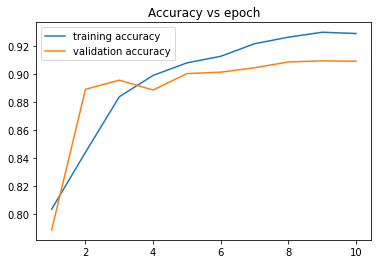

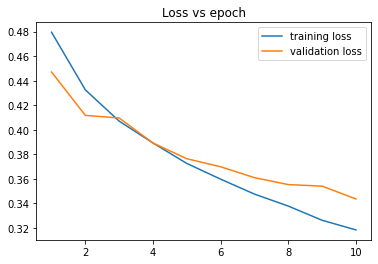

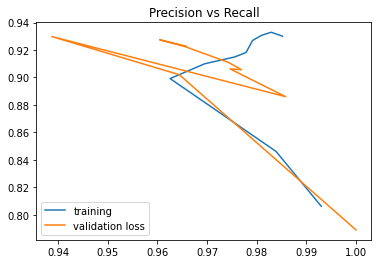

121/121 [==============================] - 2s 17ms/step - loss: 0.3435 - accuracy: 0.9093 - precision: 0.9229 - recall: 0.9657
[0.8636166652043661, 0.860930601755778, 0.9168183008829752, 0.9072004159291586, 0.9136989911397299, 0.9072004159291586]
[0.8696804245313009, 0.8708509405454, 0.9418408672014872, 0.9428947369257609, 0.9174950917561849, 0.9245075384775797]
[0.9810574054718018, 0.9762364427248637, 0.9545051256815592, 0.9403720696767172, 0.9796448548634847, 0.9619871973991394]


In [ ]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits = 3, shuffle = True)

# Separate the sentences and the labels
sentences, labels = list(pad_rev), list(sentiment_label[0])

# kfold.split() will return set indices for each split
models = [cnn_gru, cnn_bilstm, bigru, cnn_bigru, tcn_model, tcn_bigru]
precision = [ [] for _ in range(len(models))]
acc = [ [] for _ in range(len(models))]
recall = [ [] for _ in range(len(models))]

callbacks = tf.keras.callbacks.EarlyStopping(
            monitor='val_accuracy',
            min_delta=0,
            patience=5, verbose=2,
            mode='auto',
            restore_best_weights=True)

for train, test in kfold.split(sentences):

    x_train, x_test = [], []
    y_train, y_test = [], []

    for i in train:
        x_train.append(sentences[i])
        y_train.append(labels[i])

    for i in test:
        x_test.append(sentences[i])
        y_test.append(labels[i])

    # Turn the labels into a numpy array
    y_train = np.array(y_train)
    y_test = np.array(y_test)
    x_train = np.reshape(x_train, (len(y_train), 50))
    x_test = np.reshape(x_test, (len(y_test), 50))


    '''lstm = lstm()
    cnn = cnn_1d()
    dnn = dnn()
    bilstm = bilstm()
    cnn_lstm = cnn_lstm()
    gru = gru()
    cnn_gru = cnn_gru()
    cnn_bilstm = cnn_bilstm()
    bigru = bigru()
    cnn_bigru = cnn_bigru()
    tcn = tcn_model()
    tcn_bigru = tcn_bigru()
    tcn_bilstm = tcn_bilstm()
    tcn_lstm = tcn_lstm()
    tcn_gru = tcn_gru()'''

    for i in range(len(models)):
      model = models[i]()
      print(i)
      hist = model.fit(x_train,y_train,epochs=EPOCHS,batch_size = BATCH_SIZE,callbacks=[callbacks], validation_data=(x_test,y_test))
      n = len(hist.history['accuracy'])

      plt.figure()
      plt.plot(range(1,n+1), hist.history['accuracy'], label='training accuracy')
      plt.plot(range(1,n+1),hist.history['val_accuracy'], label='validation accuracy')
      plt.legend()
      plt.title("Accuracy vs epoch")
      plt.show()

      plt.figure()
      plt.plot(range(1,n+1), hist.history['loss'], label='training loss')
      plt.plot(range(1,n+1),hist.history['val_loss'], label='validation loss')
      plt.legend()
      plt.title("Loss vs epoch")
      plt.show()

      plt.figure()
      plt.plot(hist.history['recall'], hist.history['precision'], label='training')
      plt.plot(hist.history['val_recall'], hist.history['val_precision'], label='validation loss')
      plt.title("Precision vs Recall")
      plt.legend()
      plt.show()

      l, a, p, r = model.evaluate(x_test, y_test)
      acc[i].append(a)
      precision[i].append(p)
      recall[i].append(r)

mean_acc_list = []
mean_prec_list = []
mean_rec_list = []

for i in range(len(models)):
  mean_acc_list.append(np.array(acc[i]).mean())
  mean_prec_list.append(np.array(precision[i]).mean())
  mean_rec_list.append(np.array(recall[i]).mean())

print(mean_acc_list)
print(mean_prec_list)
print(mean_rec_list)

In [ ]:
import tensorflow as tf

BATCH_SIZE = 25
OPT = tf.keras.optimizers.Adam(learning_rate=1e-4)
EPOCHS = 15

0
Epoch 1/15
308/308 [==============================] - 18s 31ms/step - loss: 0.5750 - accuracy: 0.7651 - precision: 0.7951 - recall: 0.9484 - val_loss: 0.5450 - val_accuracy: 0.7996 - val_precision: 0.7995 - val_recall: 1.0000
Epoch 2/15
308/308 [==============================] - 8s 26ms/step - loss: 0.5419 - accuracy: 0.8034 - precision: 0.8022 - recall: 0.9984 - val_loss: 0.5248 - val_accuracy: 0.8170 - val_precision: 0.8143 - val_recall: 0.9987
Epoch 3/15
308/308 [==============================] - 8s 26ms/step - loss: 0.5237 - accuracy: 0.8219 - precision: 0.8200 - recall: 0.9936 - val_loss: 0.5074 - val_accuracy: 0.8378 - val_precision: 0.8322 - val_recall: 0.9984
Epoch 4/15
308/308 [==============================] - 8s 25ms/step - loss: 0.5090 - accuracy: 0.8248 - precision: 0.8221 - recall: 0.9943 - val_loss: 0.4916 - val_accuracy: 0.8118 - val_precision: 0.8099 - val_recall: 0.9990
Epoch 5/15
308/308 [==============================] - 8s 25ms/step - loss: 0.4959 - accuracy: 0.7

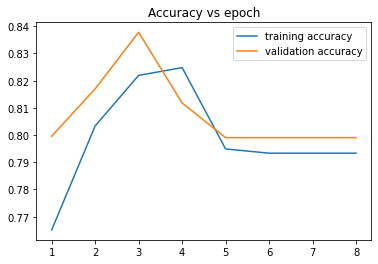

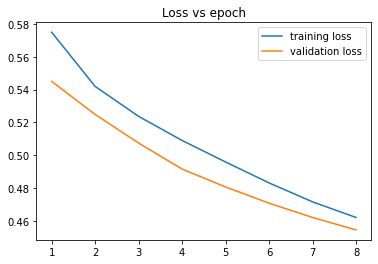

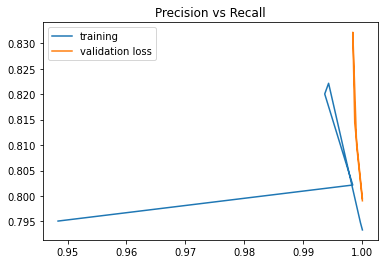

121/121 [==============================] - 1s 7ms/step - loss: 0.5074 - accuracy: 0.8378 - precision: 0.8322 - recall: 0.9984
1
Epoch 1/15
308/308 [==============================] - 10s 25ms/step - loss: 0.5175 - accuracy: 0.7923 - precision: 0.7937 - recall: 0.9975 - val_loss: 0.5072 - val_accuracy: 0.7991 - val_precision: 0.7991 - val_recall: 1.0000
Epoch 2/15
308/308 [==============================] - 7s 23ms/step - loss: 0.5108 - accuracy: 0.7933 - precision: 0.7933 - recall: 1.0000 - val_loss: 0.5025 - val_accuracy: 0.7991 - val_precision: 0.7991 - val_recall: 1.0000
Epoch 3/15
308/308 [==============================] - 7s 23ms/step - loss: 0.5102 - accuracy: 0.7933 - precision: 0.7933 - recall: 1.0000 - val_loss: 0.5022 - val_accuracy: 0.7991 - val_precision: 0.7991 - val_recall: 1.0000
Epoch 4/15
308/308 [==============================] - 7s 23ms/step - loss: 0.5105 - accuracy: 0.7933 - precision: 0.7933 - recall: 1.0000 - val_loss: 0.5024 - val_accuracy: 0.7991 - val_precision:

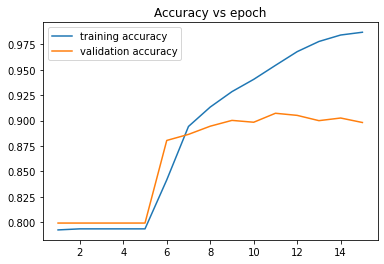

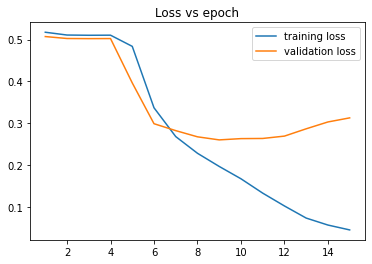

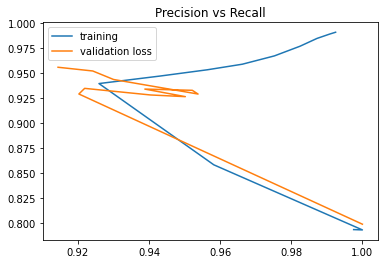

121/121 [==============================] - 1s 8ms/step - loss: 0.3126 - accuracy: 0.8981 - precision: 0.9561 - recall: 0.9144
2
Epoch 1/15
308/308 [==============================] - 26s 56ms/step - loss: 0.6722 - accuracy: 0.8093 - precision: 0.8572 - recall: 0.9115 - val_loss: 0.6551 - val_accuracy: 0.8708 - val_precision: 0.8822 - val_recall: 0.9675
Epoch 2/15
308/308 [==============================] - 15s 47ms/step - loss: 0.6429 - accuracy: 0.8850 - precision: 0.9101 - recall: 0.9487 - val_loss: 0.6359 - val_accuracy: 0.8861 - val_precision: 0.9091 - val_recall: 0.9528
Epoch 3/15
308/308 [==============================] - 15s 47ms/step - loss: 0.6263 - accuracy: 0.8982 - precision: 0.9146 - recall: 0.9615 - val_loss: 0.6232 - val_accuracy: 0.8893 - val_precision: 0.9042 - val_recall: 0.9636
Epoch 4/15
308/308 [==============================] - 15s 49ms/step - loss: 0.6135 - accuracy: 0.9036 - precision: 0.9206 - recall: 0.9613 - val_loss: 0.6121 - val_accuracy: 0.8893 - val_precisi

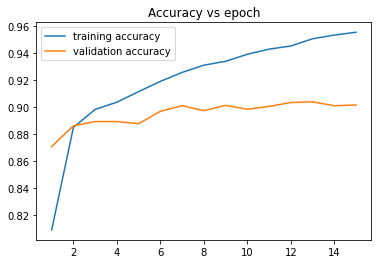

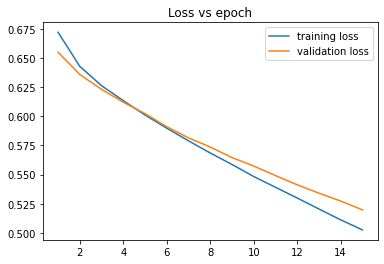

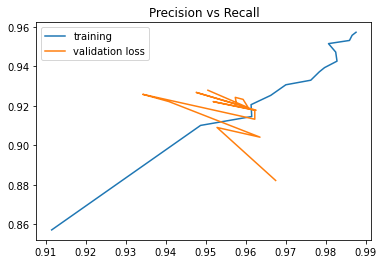

121/121 [==============================] - 2s 17ms/step - loss: 0.5198 - accuracy: 0.9015 - precision: 0.9279 - recall: 0.9506
3
Epoch 1/15
308/308 [==============================] - 18s 43ms/step - loss: 0.4826 - accuracy: 0.7933 - precision: 0.7933 - recall: 1.0000 - val_loss: 0.4182 - val_accuracy: 0.7991 - val_precision: 0.7991 - val_recall: 1.0000
Epoch 2/15
308/308 [==============================] - 13s 42ms/step - loss: 0.4312 - accuracy: 0.7933 - precision: 0.7933 - recall: 1.0000 - val_loss: 0.4011 - val_accuracy: 0.7991 - val_precision: 0.7991 - val_recall: 1.0000
Epoch 3/15
308/308 [==============================] - 12s 38ms/step - loss: 0.4223 - accuracy: 0.7933 - precision: 0.7933 - recall: 1.0000 - val_loss: 0.3949 - val_accuracy: 0.7991 - val_precision: 0.7991 - val_recall: 1.0000
Epoch 4/15
308/308 [==============================] - 12s 38ms/step - loss: 0.4167 - accuracy: 0.7933 - precision: 0.7933 - recall: 1.0000 - val_loss: 0.3923 - val_accuracy: 0.7991 - val_precis

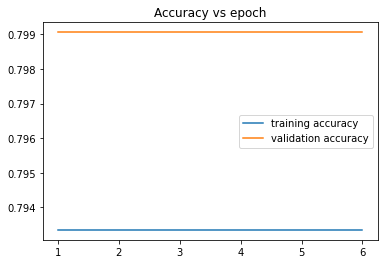

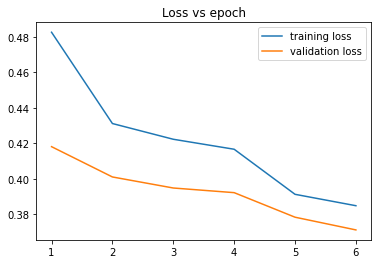

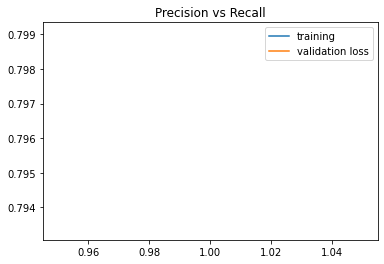

121/121 [==============================] - 2s 15ms/step - loss: 0.4182 - accuracy: 0.7991 - precision: 0.7991 - recall: 1.0000
4
Epoch 1/15
308/308 [==============================] - 18s 43ms/step - loss: 0.6924 - accuracy: 0.7316 - precision: 0.7943 - recall: 0.8929 - val_loss: 0.6684 - val_accuracy: 0.7991 - val_precision: 0.7991 - val_recall: 1.0000
Epoch 2/15
308/308 [==============================] - 12s 38ms/step - loss: 0.6627 - accuracy: 0.7933 - precision: 0.7933 - recall: 1.0000 - val_loss: 0.6557 - val_accuracy: 0.7991 - val_precision: 0.7991 - val_recall: 1.0000
Epoch 3/15
  7/308 [..............................] - ETA: 9s - loss: 0.6545 - accuracy: 0.8114 - precision: 0.8114 - recall: 1.0000 

In [ ]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits = 3, shuffle = True)

# Separate the sentences and the labels
sentences, labels = list(pad_rev), list(sentiment_label[0])

# kfold.split() will return set indices for each split
# [cnn_1d, dnn, bilstm, cnn_lstm, gru, cnn_gru, cnn_bilstm, bigru, cnn_bigru, tcn_model, tcn_bigru, tcn_bilstm, tcn_lstm, tcn_gru, tcn_cnn]
models = [cnn_lstm, gru, tcn_bilstm, tcn_lstm, tcn_gru, tcn_cnn]
precision = [ [] for _ in range(len(models))]
acc = [ [] for _ in range(len(models))]
recall = [ [] for _ in range(len(models))]

callbacks = tf.keras.callbacks.EarlyStopping(
            monitor='val_accuracy',
            min_delta=0,
            patience=5, verbose=2,
            mode='auto',
            restore_best_weights=True)

for train, test in kfold.split(sentences):

    x_train, x_test = [], []
    y_train, y_test = [], []

    for i in train:
        x_train.append(sentences[i])
        y_train.append(labels[i])

    for i in test:
        x_test.append(sentences[i])
        y_test.append(labels[i])

    # Turn the labels into a numpy array
    y_train = np.array(y_train)
    y_test = np.array(y_test)
    x_train = np.reshape(x_train, (len(y_train), 50))
    x_test = np.reshape(x_test, (len(y_test), 50))


    '''lstm = lstm()
    cnn = cnn_1d()
    dnn = dnn()
    bilstm = bilstm()
    cnn_lstm = cnn_lstm()
    gru = gru()
    cnn_gru = cnn_gru()
    cnn_bilstm = cnn_bilstm()
    bigru = bigru()
    cnn_bigru = cnn_bigru()
    tcn = tcn_model()
    tcn_bigru = tcn_bigru()
    tcn_bilstm = tcn_bilstm()
    tcn_lstm = tcn_lstm()
    tcn_gru = tcn_gru()'''

    for i in range(len(models)):
      model = models[i]()
      print(i)
      hist = model.fit(x_train,y_train,epochs=EPOCHS,batch_size = BATCH_SIZE,callbacks=[callbacks], validation_data=(x_test,y_test))
      n = len(hist.history['accuracy'])

      plt.figure()
      plt.plot(range(1,n+1), hist.history['accuracy'], label='training accuracy')
      plt.plot(range(1,n+1),hist.history['val_accuracy'], label='validation accuracy')
      plt.legend()
      plt.title("Accuracy vs epoch")
      plt.show()

      plt.figure()
      plt.plot(range(1,n+1), hist.history['loss'], label='training loss')
      plt.plot(range(1,n+1),hist.history['val_loss'], label='validation loss')
      plt.legend()
      plt.title("Loss vs epoch")
      plt.show()

      plt.figure()
      plt.plot(hist.history['recall'], hist.history['precision'], label='training')
      plt.plot(hist.history['val_recall'], hist.history['val_precision'], label='validation loss')
      plt.title("Precision vs Recall")
      plt.legend()
      plt.show()

      l, a, p, r = model.evaluate(x_test, y_test)
      acc[i].append(a)
      precision[i].append(p)
      recall[i].append(r)

mean_acc_list = []
mean_prec_list = []
mean_rec_list = []

for i in range(len(models)):
  mean_acc_list.append(np.array(acc[i]).mean())
  mean_prec_list.append(np.array(precision[i]).mean())
  mean_rec_list.append(np.array(recall[i]).mean())

print(mean_acc_list)
print(mean_prec_list)
print(mean_rec_list)

In [ ]:
BATCH_SIZE = 25
OPT = tf.keras.optimizers.Adam(learning_rate=1e-5)
EPOCHS = 15

NameError: ignored

In [ ]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits = 3, shuffle = True)

# Separate the sentences and the labels
sentences, labels = list(pad_rev), list(sentiment_label[0])

# kfold.split() will return set indices for each split
# [cnn_1d, dnn, bilstm, cnn_lstm, gru, cnn_gru, cnn_bilstm, bigru, cnn_bigru, tcn_model, tcn_bigru, tcn_bilstm, tcn_lstm, tcn_gru, tcn_cnn]
models = [tcn_lstm, tcn_gru, tcn_cnn]
precision = [ [] for _ in range(len(models))]
acc = [ [] for _ in range(len(models))]
recall = [ [] for _ in range(len(models))]

callbacks = tf.keras.callbacks.EarlyStopping(
            monitor='val_accuracy',
            min_delta=0,
            patience=5, verbose=2,
            mode='auto',
            restore_best_weights=True)

for train, test in kfold.split(sentences):

    x_train, x_test = [], []
    y_train, y_test = [], []

    for i in train:
        x_train.append(sentences[i])
        y_train.append(labels[i])

    for i in test:
        x_test.append(sentences[i])
        y_test.append(labels[i])

    # Turn the labels into a numpy array
    y_train = np.array(y_train)
    y_test = np.array(y_test)
    x_train = np.reshape(x_train, (len(y_train), 50))
    x_test = np.reshape(x_test, (len(y_test), 50))


    '''lstm = lstm()
    cnn = cnn_1d()
    dnn = dnn()
    bilstm = bilstm()
    cnn_lstm = cnn_lstm()
    gru = gru()
    cnn_gru = cnn_gru()
    cnn_bilstm = cnn_bilstm()
    bigru = bigru()
    cnn_bigru = cnn_bigru()
    tcn = tcn_model()
    tcn_bigru = tcn_bigru()
    tcn_bilstm = tcn_bilstm()
    tcn_lstm = tcn_lstm()
    tcn_gru = tcn_gru()'''

    for i in range(len(models)):
      model = models[i]()
      print(i)
      hist = model.fit(x_train,y_train,epochs=EPOCHS,batch_size = BATCH_SIZE,callbacks=[callbacks], validation_data=(x_test,y_test))
      n = len(hist.history['accuracy'])

      plt.figure()
      plt.plot(range(1,n+1), hist.history['accuracy'], label='training accuracy')
      plt.plot(range(1,n+1),hist.history['val_accuracy'], label='validation accuracy')
      plt.legend()
      plt.title("Accuracy vs epoch")
      plt.show()

      plt.figure()
      plt.plot(range(1,n+1), hist.history['loss'], label='training loss')
      plt.plot(range(1,n+1),hist.history['val_loss'], label='validation loss')
      plt.legend()
      plt.title("Loss vs epoch")
      plt.show()

      plt.figure()
      plt.plot(hist.history['recall'], hist.history['precision'], label='training')
      plt.plot(hist.history['val_recall'], hist.history['val_precision'], label='validation loss')
      plt.title("Precision vs Recall")
      plt.legend()
      plt.show()

      l, a, p, r = model.evaluate(x_test, y_test)
      acc[i].append(a)
      precision[i].append(p)
      recall[i].append(r)

mean_acc_list = []
mean_prec_list = []
mean_rec_list = []

for i in range(len(models)):
  mean_acc_list.append(np.array(acc[i]).mean())
  mean_prec_list.append(np.array(precision[i]).mean())
  mean_rec_list.append(np.array(recall[i]).mean())

print(mean_acc_list)
print(mean_prec_list)
print(mean_rec_list)

NameError: ignored

# Graphs